# **Project Name**    -  Customer Satisfaction Analysis and Prediction Using Machine Learning


##### **Project Type**    - Classification
##### **Contribution**    - Individual
##### **Done by**         - Anusha N

## Project Summary

This machine learning initiative aims to model and predict customer satisfaction levels using Flipkart's customer support interaction records. To build a robust predictive framework, we restructured the multi-class CSAT ratings into a simplified binary objective: **Satisfied** and **At-Risk** customers. The exploratory and preprocessing phases involved rigorous data auditing, strategic imputation of missing fields, target-oriented feature construction, text-based sentiment feature extraction, and categorical encoding schemes.

We trained and evaluated three distinct classification architectures: **Logistic Regression, Random Forest, and XGBoost**. Given the significant class imbalance in customer feedback, our evaluation prioritized recall and F1-score on the underrepresented 'At-Risk' cohort rather than relying strictly on overall classification accuracy. This ensures that the model successfully flags potentially churn-prone or unhappy clients.

Our experimental results show that **the optimized XGBoost classifier achieves the most balanced performance in identifying vulnerable customer relationships**. Important features driving our classification decisions include ticket response velocity, issue classification, and the sentiment of user-submitted feedback. This predictive pipeline offers actionable customer service insights, enabling operational teams to proactively resolve disputes and mitigate churn risk.

# **GitHub Link -**

https://github.com/anushanarne/Flipkart-customer-satisfaction-analysis-ml.git


# **Problem Statement**


## Problem Statement

For major online retail and e-commerce platforms, maintaining high levels of customer satisfaction is essential for cultivating long-term user retention and operational health. However, assessing the success of individual customer service interactions is complicated by multi-dimensional factors, including ticket categories, communication channels, response and handling times, agent profiles, and specific customer inquiries.

The goal of this analytical project is twofold:
1. Conduct diagnostic exploratory analysis on customer support logs to uncover systemic bottlenecks, evaluate the impact of operational lag on sentiment, and map patterns of customer dissatisfaction.
2. Design and deploy a machine learning classification engine capable of anticipating at-risk support outcomes using real-time transactional and operational parameters.

By converting these predictive signals into actionable operational strategies, the business can prioritize critical tickets, restructure agent allocations, and systematically enhance overall service quality.

# **General Guidelines**

1.   Well-structured, formatted, and commented code is required.
2.   Exception Handling, Production Grade Code & Deployment Ready Code will be a plus. Those students will be awarded some additional credits.
     
     The additional credits will have advantages over other students during Star Student selection.
       
             [ Note: - Deployment Ready Code is defined as, the whole .ipynb notebook should be executable in one go
                       without a single error logged. ]

3.   Each and every logic should have proper comments.
4. You may add as many number of charts you want. Make Sure for each and every chart the following format should be answered.
        

```
# Chart visualization code
```
            

*   Why did you pick the specific chart?
*   What is/are the insight(s) found from the chart?
* Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

5. You have to create at least 15 logical & meaningful charts having important insights.


[ Hints : - Do the Vizualization in  a structured way while following "UBM" Rule.

U - Univariate Analysis,

B - Bivariate Analysis (Numerical - Categorical, Numerical - Numerical, Categorical - Categorical)

M - Multivariate Analysis
 ]





6. You may add more ml algorithms for model creation. Make sure for each and every algorithm, the following format should be answered.


*   Explain the ML Model used and it's performance using Evaluation metric Score Chart.


*   Cross- Validation & Hyperparameter Tuning

*   Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

*   Explain each evaluation metric's indication towards business and the business impact pf the ML model used.




















# ***Let's Begin !***

## ***1. Know Your Data***

### Import Libraries

In [ ]:
# IMPORTING REQUIRED LIBRARIES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

# Visualization settings
sns.set_theme(style="whitegrid")

warnings.filterwarnings('ignore')

### Dataset Loading

In [ ]:
# LOADING DATASET & IMMEDIATE DATA WRANGLING

import subprocess
import sys

# Ensure vaderSentiment is installed
try:
    from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "vaderSentiment"])
    from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

import numpy as np
import pandas as pd

data_url = (
    "https://raw.githubusercontent.com/anushanarne/Flipkart-customer-satisfaction-analysis-ml/refs/heads/main/Customer_support_data_flpkrt.csv"
)

try:
    df = pd.read_csv(data_url)
    print("Dataset loaded successfully. Starting preprocessing...")

    # Drop almost-empty columns
    if 'connected_handling_time' in df.columns:
        df = df.drop(columns=['connected_handling_time'])

    # Handle missing values
    df['Customer Remarks'] = df['Customer Remarks'].fillna('')
    df['Item_price'] = df['Item_price'].fillna(0)
    df['has_order_context'] = df['Order_id'].notna().astype(int)
    df['has_remark'] = df['Customer Remarks'].str.strip().ne('').astype(int)

    # Convert timestamps to datetime
    df['Issue_reported at'] = pd.to_datetime(df['Issue_reported at'], format='mixed', dayfirst=True, errors='coerce')
    df['issue_responded'] = pd.to_datetime(df['issue_responded'], format='mixed', dayfirst=True, errors='coerce')

    # Calculate time features
    df['report_hour'] = df['Issue_reported at'].dt.hour
    df['report_dow'] = df['Issue_reported at'].dt.dayofweek

    # Calculate response time in minutes
    df['response_time_min'] = (df['issue_responded'] - df['Issue_reported at']).dt.total_seconds() / 60.0
    df.loc[df['response_time_min'] < 0, 'response_time_min'] = np.nan
    df['response_time_min'] = df['response_time_min'].fillna(df.groupby('category')['response_time_min'].transform('median'))
    df['response_time_min'] = df['response_time_min'].fillna(df['response_time_min'].median())

    # Sentiment analysis features
    sia = SentimentIntensityAnalyzer()
    df['remark_sentiment'] = df['Customer Remarks'].apply(lambda t: sia.polarity_scores(t)['compound'] if t else 0.0)
    df['remark_len'] = df['Customer Remarks'].str.len()

    # Define target satisfaction variable
    df['Satisfaction'] = (df['CSAT Score'] >= 4).astype(int)

    print("Data loaded and engineered with 'Satisfaction', 'response_time_min', and 'remark_sentiment'. Ready for visualizations!")

except Exception as e:
    print(f"Error while loading or preprocessing the dataset: {e}")

Dataset loaded successfully. Starting preprocessing...
Data loaded and engineered with 'Satisfaction', 'response_time_min', and 'remark_sentiment'. Ready for visualizations!


In [ ]:
# Print the list of all available columns in the engineered DataFrame to verify their names
print(df.columns.tolist())

['Unique id', 'channel_name', 'category', 'Sub-category', 'Customer Remarks', 'Order_id', 'order_date_time', 'Issue_reported at', 'issue_responded', 'Survey_response_Date', 'Customer_City', 'Product_category', 'Item_price', 'Agent_name', 'Supervisor', 'Manager', 'Tenure Bucket', 'Agent Shift', 'CSAT Score', 'has_order_context', 'has_remark', 'report_hour', 'report_dow', 'response_time_min', 'remark_sentiment', 'remark_len', 'Satisfaction']


In [ ]:
# Display the first few rows of the reported, responded, and computed response time columns for a quick sanity check
print(df[['Issue_reported at', 'issue_responded', 'response_time_min']].head())

    Issue_reported at     issue_responded  response_time_min
0 2023-08-01 11:13:00 2023-08-01 11:47:00               34.0
1 2023-08-01 12:52:00 2023-08-01 12:54:00                2.0
2 2023-08-01 20:16:00 2023-08-01 20:38:00               22.0
3 2023-08-01 20:56:00 2023-08-01 21:16:00               20.0
4 2023-08-01 10:30:00 2023-08-01 10:32:00                2.0


In [ ]:
# Step 1: Parse datetime fields using mixed formats and handling invalid entries gracefully
df['Issue_reported at'] = pd.to_datetime(df['Issue_reported at'], format='mixed', dayfirst=True, errors='coerce')
df['issue_responded'] = pd.to_datetime(df['issue_responded'], format='mixed', dayfirst=True, errors='coerce')

# Step 2: Compute response duration in minutes from the time difference
df['response_time_min'] = (df['issue_responded'] - df['Issue_reported at']).dt.total_seconds() / 60

# Step 3: Replace any negative durations (which indicate data entry errors) with NaN
df.loc[df['response_time_min'] < 0, 'response_time_min'] = np.nan

# Step 4: Fill missing response times using the median duration calculated per issue category
df['response_time_min'] = df['response_time_min'].fillna(df.groupby('category')['response_time_min'].transform('median'))

# Step 5: Fill any remaining missing values with the overall global median response time
df['response_time_min'] = df['response_time_min'].fillna(df['response_time_min'].median())

# Step 6: Print first five rows of response times to verify calculations
print(df[['response_time_min']].head())

   response_time_min
0               34.0
1                2.0
2               22.0
3               20.0
4                2.0


In [ ]:
# Check for any remaining null values in the response_time_min column
print(df['response_time_min'].isnull().sum())

# Display descriptive statistics for response_time_min to understand scale and spread
print(df['response_time_min'].describe())

0
count    85907.000000
mean       169.860599
std        555.728179
min          0.000000
25%          2.000000
50%          6.000000
75%         35.000000
max       5758.000000
Name: response_time_min, dtype: float64


In [ ]:
# Calculate the 25th (Q1) and 75th (Q3) percentiles of response times
Q1 = df['response_time_min'].quantile(0.25)
Q3 = df['response_time_min'].quantile(0.75)

# Calculate the Interquartile Range (IQR)
IQR = Q3 - Q1

# Define the upper limit for identifying statistical outliers
upper = Q3 + 1.5 * IQR

# Output limits and total number of outliers detected
print("Upper limit:", upper)
print("Outliers:", (df['response_time_min'] > upper).sum())

Upper limit: 84.5
Outliers: 16136


In [ ]:
# Isolate outlier rows that sit above our calculated upper limit threshold
outliers = df[df['response_time_min'] > upper]

# Output key descriptive stats specifically for the outliers subgroup
print("Outlier count:", len(outliers))
print("Minimum:", outliers['response_time_min'].min())
print("Maximum:", outliers['response_time_min'].max())
print("Median:", outliers['response_time_min'].median())
print("Mean:", outliers['response_time_min'].mean())

Outlier count: 16136
Minimum: 85.0
Maximum: 5758.0
Median: 458.0
Mean: 860.9884729796728


### Dataset First View

In [ ]:
# Display the first five records of the DataFrame to inspect columns and values
df.head()

,Unique id,channel_name,category,Sub-category,Customer Remarks,Order_id,order_date_time,Issue_reported at,issue_responded,Survey_response_Date,Customer_City,Product_category,Item_price,Agent_name,Supervisor,Manager,Tenure Bucket,Agent Shift,CSAT Score,has_order_context,has_remark,report_hour,report_dow,response_time_min,remark_sentiment,remark_len,Satisfaction
0,7e9ae164-6a8b-4521-a2d4-58f7c9fff13f,Outcall,Product Queries,Life Insurance,,c27c9bb4-fa36-4140-9f1f-21009254ffdb,NaN,2023-08-01 11:13:00,2023-08-01 11:47:00,01-Aug-23,NaN,NaN,0.0,Richard Buchanan,Mason Gupta,Jennifer Nguyen,On Job Training,Morning,5,1,0,11,1,34.0,0.0,0,1
1,b07ec1b0-f376-43b6-86df-ec03da3b2e16,Outcall,Product Queries,Product Specific Information,,d406b0c7-ce17-4654-b9de-f08d421254bd,NaN,2023-08-01 12:52:00,2023-08-01 12:54:00,01-Aug-23,NaN,NaN,0.0,Vicki Collins,Dylan Kim,Michael Lee,>90,Morning,5,1,0,12,1,2.0,0.0,0,1
2,200814dd-27c7-4149-ba2b-bd3af3092880,Inbound,Order Related,Installation/demo,,c273368d-b961-44cb-beaf-62d6fd6c00d5,NaN,2023-08-01 20:16:00,2023-08-01 20:38:00,01-Aug-23,NaN,NaN,0.0,Duane Norman,Jackson Park,William Kim,On Job Training,Evening,5,1,0,20,1,22.0,0.0,0,1
3,eb0d3e53-c1ca-42d3-8486-e42c8d622135,Inbound,Returns,Reverse Pickup Enquiry,,5aed0059-55a4-4ec6-bb54-97942092020a,NaN,2023-08-01 20:56:00,2023-08-01 21:16:00,01-Aug-23,NaN,NaN,0.0,Patrick Flores,Olivia Wang,John Smith,>90,Evening,5,1,0,20,1,20.0,0.0,0,1
4,ba903143-1e54-406c-b969-46c52f92e5df,Inbound,Cancellation,Not Needed,,e8bed5a9-6933-4aff-9dc6-ccefd7dcde59,NaN,2023-08-01 10:30:00,2023-08-01 10:32:00,01-Aug-23,NaN,NaN,0.0,Christopher Sanchez,Austin Johnson,Michael Lee,0-30,Morning,5,1,0,10,1,2.0,0.0,0,1


In [ ]:
# Display the final five records of the DataFrame to ensure alignment at the tail
df.tail()

,Unique id,channel_name,category,Sub-category,Customer Remarks,Order_id,order_date_time,Issue_reported at,issue_responded,Survey_response_Date,Customer_City,Product_category,Item_price,Agent_name,Supervisor,Manager,Tenure Bucket,Agent Shift,CSAT Score,has_order_context,has_remark,report_hour,report_dow,response_time_min,remark_sentiment,remark_len,Satisfaction
85902,505ea5e7-c475-4fac-ac36-1d19a4cb610f,Inbound,Refund Related,Refund Enquiry,,1b5a2b9c-a95f-405f-a42e-5b1b693f3dc9,NaN,2023-08-30 23:20:00,2023-08-31 07:22:00,31-Aug-23,NaN,NaN,0.0,Brandon Leon,Ethan Tan,William Kim,On Job Training,Morning,4,1,0,23,2,482.0,0.0000,0,1
85903,44b38d3f-1523-4182-aba2-72917586647c,Inbound,Order Related,Seller Cancelled Order,Supported team customer executive good,d0e8a817-96d5-4ace-bb82-adec50398e22,NaN,2023-08-31 08:15:00,2023-08-31 08:17:00,31-Aug-23,NaN,NaN,0.0,Linda Foster,Noah Patel,Emily Chen,>90,Morning,5,1,1,8,3,2.0,0.6369,40,1
85904,723bce2c-496c-4aa8-a64b-ca17004528f0,Inbound,Order Related,Order status enquiry,need to improve with proper details.,bdefe788-ccec-4eda-8ca4-51045e68db8a,NaN,2023-08-31 18:57:00,2023-08-31 19:02:00,31-Aug-23,NaN,NaN,0.0,Kimberly Martinez,Aiden Patel,Olivia Tan,On Job Training,Evening,5,1,1,18,3,5.0,0.4404,36,1
85905,707528ee-6873-4192-bfa9-a491f1c08ab5,Inbound,Feedback,UnProfessional Behaviour,,a031ec28-0c5e-450e-95b2-592342c40bc4,NaN,2023-08-31 19:59:00,2023-08-31 20:00:00,31-Aug-23,NaN,NaN,0.0,Daniel Martin,Olivia Suzuki,Olivia Tan,>90,Morning,4,1,0,19,3,1.0,0.0000,0,1
85906,07c7a878-0d5a-42e0-97ef-de59abec0238,Inbound,Returns,Reverse Pickup Enquiry,,3230db30-f8da-4c44-8636-ec76d1d3d4f3,NaN,2023-08-31 23:36:00,2023-08-31 23:37:00,31-Aug-23,NaN,NaN,0.0,Elizabeth Guerra,Nathan Patel,Jennifer Nguyen,On Job Training,Evening,5,1,0,23,3,1.0,0.0000,0,1


### Dataset Rows & Columns count

In [ ]:
# Dataset Rows & Columns count

print(f"Number of rows : {df.shape[0]}")
print(f"Number of columns : {df.shape[1]}")

Number of rows : 85907
Number of columns : 27


### Dataset Information

In [ ]:
# Output summary information of the dataset schema, including column types and non-null counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 85907 entries, 0 to 85906
Data columns (total 27 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   Unique id             85907 non-null  object        
 1   channel_name          85907 non-null  object        
 2   category              85907 non-null  object        
 3   Sub-category          85907 non-null  object        
 4   Customer Remarks      85907 non-null  object        
 5   Order_id              67675 non-null  object        
 6   order_date_time       17214 non-null  object        
 7   Issue_reported at     85907 non-null  datetime64[ns]
 8   issue_responded       85907 non-null  datetime64[ns]
 9   Survey_response_Date  85907 non-null  object        
 10  Customer_City         17079 non-null  object        
 11  Product_category      17196 non-null  object        
 12  Item_price            85907 non-null  float64       
 13  Agent_name      

#### Duplicate Values

In [ ]:
# Compute and output the sum of exact duplicate rows in the entire dataset
duplicate_count = df.duplicated().sum()
print(f"Number of duplicate rows: {duplicate_count}")

Number of duplicate rows: 0


#### Missing Values/Null Values

In [ ]:
# Compute total missing values and their respective percentage across all features
missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2)
})

# Display summary sorted by the number of missing items in descending order
display(missing_summary.sort_values("Missing Count", ascending=False))

,Missing Count,Missing Percentage
Customer_City,68828,80.12
Product_category,68711,79.98
order_date_time,68693,79.96
Order_id,18232,21.22
category,0,0.00
Unique id,0,0.00
channel_name,0,0.00
Sub-category,0,0.00
Issue_reported at,0,0.00
issue_responded,0,0.00


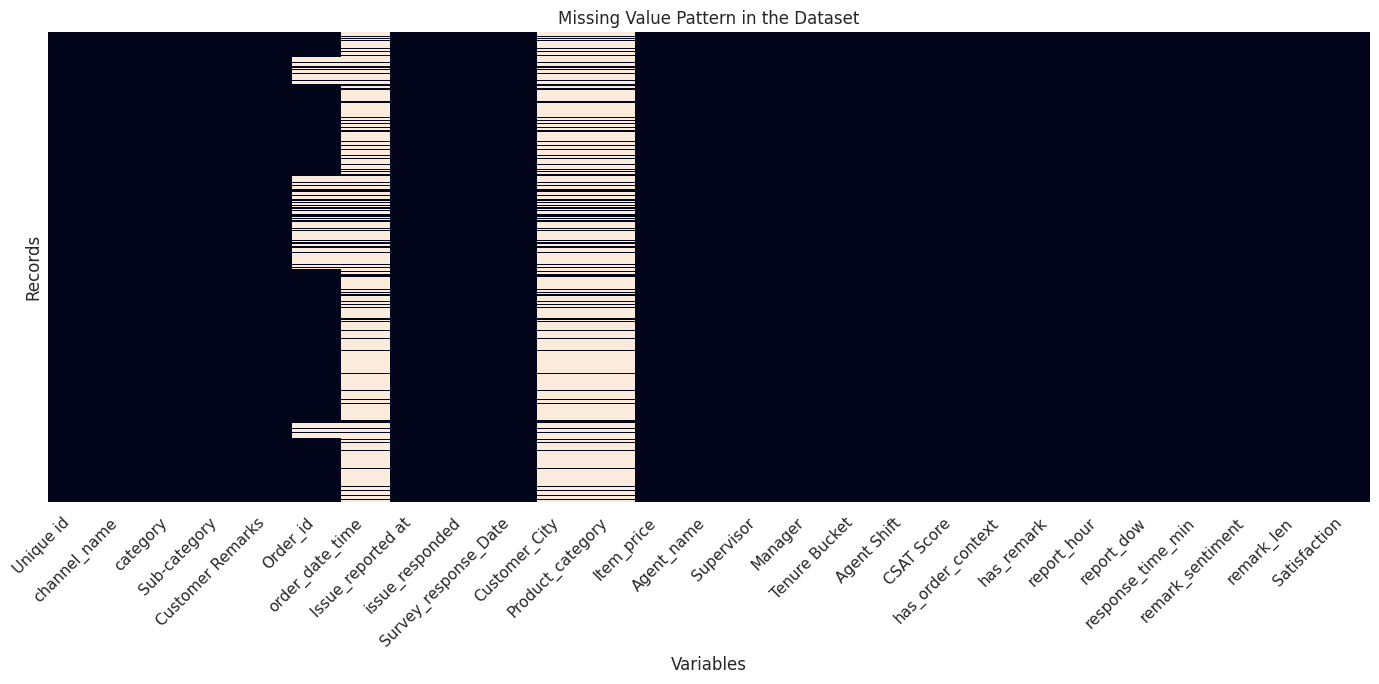

In [ ]:
# Configure figure size for the heatmap
plt.figure(figsize=(14, 7))

# Generate a binary heatmap visualizing missing values (null values appear highlighted)
sns.heatmap(
    df.isnull(),
    cbar=False,
    yticklabels=False
)

# Set descriptive layout parameters
plt.title("Missing Value Pattern in the Dataset")
plt.xlabel("Variables")
plt.ylabel("Records")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### What did you know about your dataset?

- The dataset contains 85,907 customer support interactions.
- It includes 20 variables covering customer details, support interactions, issue information, agent information, order information, and customer satisfaction.
- The main outcome variable is CSAT Score, representing customer satisfaction with the support experience.
- The dataset contains both categorical and numerical variables.
- Important operational variables include channel_name, category, Sub-category, connected_handling_time, Agent_name, Agent Shift, and Tenure Bucket.
- Customer and transaction-related information includes Customer_City, Product_category, Item_price, and Order_id.
- The dataset also contains multiple date/time fields (order_date_time, Issue_reported_at, issue_responded, Survey_response_Date) that can be used to derive response-time and other time-based features.
- Customer Remarks contains free-text feedback and requires special treatment because it includes both actual missing values and placeholders like None, -, and N/A.
- The dataset provides enough information for exploratory analysis of customer satisfaction and classification-based prediction of satisfaction.


## ***2. Understanding Your Variables***

In [ ]:
# Print all available columns to assist in quick variable mapping
df.columns.tolist()

['Unique id',
 'channel_name',
 'category',
 'Sub-category',
 'Customer Remarks',
 'Order_id',
 'order_date_time',
 'Issue_reported at',
 'issue_responded',
 'Survey_response_Date',
 'Customer_City',
 'Product_category',
 'Item_price',
 'Agent_name',
 'Supervisor',
 'Manager',
 'Tenure Bucket',
 'Agent Shift',
 'CSAT Score',
 'has_order_context',
 'has_remark',
 'report_hour',
 'report_dow',
 'response_time_min',
 'remark_sentiment',
 'remark_len',
 'Satisfaction']

In [ ]:
# Dataset Describe
df.describe(include = 'all').T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Unique id,85907,85907,7e9ae164-6a8b-4521-a2d4-58f7c9fff13f,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
channel_name,85907,3,Inbound,68142,NaN,NaN,NaN,NaN,NaN,NaN,NaN
category,85907,12,Returns,44097,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sub-category,85907,57,Reverse Pickup Enquiry,22389,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer Remarks,85907,18232,,57165,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Order_id,67675,67675,c27c9bb4-fa36-4140-9f1f-21009254ffdb,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_date_time,17214,13766,09/08/2023 11:55,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Issue_reported at,85907,NaN,NaN,NaN,2023-08-16 22:29:05.784394752,2023-07-28 20:42:00,2023-08-09 12:48:00,2023-08-16 18:22:00,2023-08-24 17:33:30,2023-08-31 23:58:00,NaN
issue_responded,85907,NaN,NaN,NaN,2023-08-17 00:45:58.980990976,2023-08-01 00:00:00,2023-08-09 15:02:30,2023-08-16 20:57:00,2023-08-24 19:27:00,2023-08-31 23:59:00,NaN
Survey_response_Date,85907,31,28-Aug-23,3452,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Variables Description

- **Unique id / Order_id** — identifiers for the ticket and the linked order (Order_id has many missing values)
- **channel_name** — how the ticket was raised (Email, Inbound call, Outcall)
- **category / Sub-category** — the type of issue the ticket is about (e.g. Returns, Order Related, Payments)
- **Customer Remarks** — free-text feedback left by the customer (optional, often blank)
- **Order_date_time, Issue_reported at, issue_responded, Survey_response_Date** — timestamps tracking the ticket lifecycle
- **Customer_City, Item_price, Product_category** — order/product context, only present for order-linked tickets
- **connected_handling_time** — talk-time on the call (almost entirely missing)
- **Agent_name, Supervisor, Manager, Agent Shift, Tenure Bucket** — details about the agent who handled the ticket
- **CSAT Score** — the target variable: the customer's satisfaction rating from 1 (worst) to 5 (best)

### Check Unique Values for each variable.

In [ ]:
# Calculate and list the count of unique values for every single column
df.nunique()

,0
Unique id,85907
channel_name,3
category,12
Sub-category,57
Customer Remarks,18232
Order_id,67675
order_date_time,13766
Issue_reported at,30923
issue_responded,30262
Survey_response_Date,31


## 3. ***Data Wrangling***

### Data Wrangling Code

In [ ]:
!pip install vaderSentiment

In [ ]:
# Write your code to make your dataset analysis ready.

# Drop almost-empty columns
df = df.drop(columns=['connected_handling_time'], errors='ignore') #99.72 % null values

# Handle missing values
df['Customer Remarks'] = df['Customer Remarks'].fillna('')   # empty string for text
df['Item_price'] = df['Item_price'].fillna(0)                # 0 for missing price
df['has_order_context'] = df['Order_id'].notna().astype(int)
df['has_remark'] = df['Customer Remarks'].str.strip().ne('').astype(int)

# timestamps to datetime
df['Issue_reported at'] = pd.to_datetime(df['Issue_reported at'],format='mixed', dayfirst=True,errors='coerce')
df['issue_responded'] = pd.to_datetime(df['issue_responded'],format='mixed', dayfirst=True,errors='coerce')

# hour and days of the week calculation
df['report_hour'] = df['Issue_reported at'].dt.hour
df['report_dow'] = df['Issue_reported at'].dt.dayofweek

# Sentiment score
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
sia = SentimentIntensityAnalyzer()
df['remark_sentiment'] = df['Customer Remarks'].apply(lambda t: sia.polarity_scores(t)['compound'] if t else 0.0)
df['remark_len'] = df['Customer Remarks'].str.len()

# target variable
# 1 = Satisfied (CSAT 4 or 5), 0 = At-Risk (CSAT 1, 2 or 3)
df['Satisfaction'] = (df['CSAT Score'] >= 4).astype(int)

df.head(10)

,Unique id,channel_name,category,Sub-category,Customer Remarks,Order_id,order_date_time,Issue_reported at,issue_responded,Survey_response_Date,Customer_City,Product_category,Item_price,Agent_name,Supervisor,Manager,Tenure Bucket,Agent Shift,CSAT Score,has_order_context,has_remark,report_hour,report_dow,response_time_min,remark_sentiment,remark_len,Satisfaction
0,7e9ae164-6a8b-4521-a2d4-58f7c9fff13f,Outcall,Product Queries,Life Insurance,,c27c9bb4-fa36-4140-9f1f-21009254ffdb,NaN,2023-08-01 11:13:00,2023-08-01 11:47:00,01-Aug-23,NaN,NaN,0.0,Richard Buchanan,Mason Gupta,Jennifer Nguyen,On Job Training,Morning,5,1,0,11,1,34.0,0.0000,0,1
1,b07ec1b0-f376-43b6-86df-ec03da3b2e16,Outcall,Product Queries,Product Specific Information,,d406b0c7-ce17-4654-b9de-f08d421254bd,NaN,2023-08-01 12:52:00,2023-08-01 12:54:00,01-Aug-23,NaN,NaN,0.0,Vicki Collins,Dylan Kim,Michael Lee,>90,Morning,5,1,0,12,1,2.0,0.0000,0,1
2,200814dd-27c7-4149-ba2b-bd3af3092880,Inbound,Order Related,Installation/demo,,c273368d-b961-44cb-beaf-62d6fd6c00d5,NaN,2023-08-01 20:16:00,2023-08-01 20:38:00,01-Aug-23,NaN,NaN,0.0,Duane Norman,Jackson Park,William Kim,On Job Training,Evening,5,1,0,20,1,22.0,0.0000,0,1
3,eb0d3e53-c1ca-42d3-8486-e42c8d622135,Inbound,Returns,Reverse Pickup Enquiry,,5aed0059-55a4-4ec6-bb54-97942092020a,NaN,2023-08-01 20:56:00,2023-08-01 21:16:00,01-Aug-23,NaN,NaN,0.0,Patrick Flores,Olivia Wang,John Smith,>90,Evening,5,1,0,20,1,20.0,0.0000,0,1
4,ba903143-1e54-406c-b969-46c52f92e5df,Inbound,Cancellation,Not Needed,,e8bed5a9-6933-4aff-9dc6-ccefd7dcde59,NaN,2023-08-01 10:30:00,2023-08-01 10:32:00,01-Aug-23,NaN,NaN,0.0,Christopher Sanchez,Austin Johnson,Michael Lee,0-30,Morning,5,1,0,10,1,2.0,0.0000,0,1
5,1cfde5b9-6112-44fc-8f3b-892196137a62,Email,Returns,Fraudulent User,,a2938961-2833-45f1-83d6-678d9555c603,NaN,2023-08-01 15:13:00,2023-08-01 18:39:00,01-Aug-23,NaN,NaN,0.0,Desiree Newton,Emma Park,John Smith,0-30,Morning,5,1,0,15,1,206.0,0.0000,0,1
6,11a3ffd8-1d6b-4806-b198-c60b5934c9bc,Outcall,Product Queries,Product Specific Information,,bfcb562b-9a2f-4cca-aa79-fd4e2952f901,NaN,2023-08-01 15:31:00,2023-08-01 23:52:00,01-Aug-23,NaN,NaN,0.0,Shannon Hicks,Aiden Patel,Olivia Tan,>90,Morning,5,1,0,15,1,501.0,0.0000,0,1
7,372b51a5-fa19-4a31-a4b8-a21de117d75e,Inbound,Returns,Exchange / Replacement,Very good,88537e0b-5ffa-43f9-bbe2-fe57a0f4e4ae,NaN,2023-08-01 16:17:00,2023-08-01 16:23:00,01-Aug-23,NaN,NaN,0.0,Laura Smith,Evelyn Kimura,Jennifer Nguyen,On Job Training,Evening,5,1,1,16,1,6.0,0.4927,9,1
8,6e4413db-4e16-42fc-ac92-2f402e3df03c,Inbound,Returns,Missing,Shopzilla app and it's all coustomer care serv...,e6be9713-13c3-493c-8a91-2137cbbfa7e6,NaN,2023-08-01 21:03:00,2023-08-01 21:07:00,01-Aug-23,NaN,NaN,0.0,David Smith,Nathan Patel,John Smith,>90,Split,5,1,1,21,1,4.0,0.7501,89,1
9,b0a65350-64a5-4603-8b9a-a24a4a145d08,Inbound,Shopzilla Related,General Enquiry,,c7caa804-2525-499e-b202-4c781cb68974,NaN,2023-08-01 23:31:00,2023-08-01 23:36:00,01-Aug-23,NaN,NaN,0.0,Tabitha Ayala,Amelia Tanaka,Michael Lee,31-60,Evening,5,1,0,23,1,5.0,0.0000,0,1


### What all manipulations have you done and insights you found?

## Data Manipulations
- Dropped column: connected_handling_time (mostly empty).
- Handled missing values:
  - Customer Remarks - filled with empty string.
  - Item_price - filled with 0.
- Converted timestamps: Issue_reported at, issue_responded - datetime format.
- Created target variable: Satisfaction (binary flag from CSAT Score).

## Insights
- Core fields (channel_name, category, Agent_name, etc.) are complete.
- Transactional fields (Order_id, order_date_time, Customer_City, Product_category) show high missingness.
- Customer Remarks and Item_price are now standardized for analysis.
- Time columns are clean, enabling response time or time-based feature engineering.
- Satisfaction outcome is clearly defined for classification tasks.


## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

#### Chart - 1

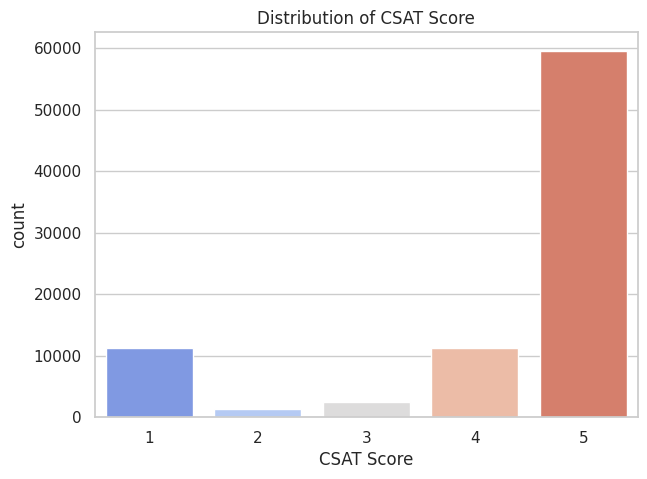

In [ ]:
# Set size of the plot window
plt.figure(figsize=(7,5))

# Use Seaborn's countplot to show count distribution of each CSAT score (1 to 5)
ax = sns.countplot(x='CSAT Score', data=df, palette='coolwarm')
plt.title('Distribution of CSAT Score')
plt.show()

##### 1. Why did you pick the specific chart?

A count plot is the simplest, clearest way to show how many tickets fall into each score category since CSAT Score is a small set of discrete values (1 to 5), a bar per value is easier to read than a histogram.

##### 2. What is/are the insight(s) found from the chart?

The distribution is heavily skewed towards 5 and Scores of 2 and 3 are very rare.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, it's a positive signal that the large majority of tickets are already rated well, meaning the core support process is generally working. But it also means a model that always predicts '5' would look deceptively accurate, which could hide real problems if the business relied on accuracy alone as a KPI.

#### Chart - 2

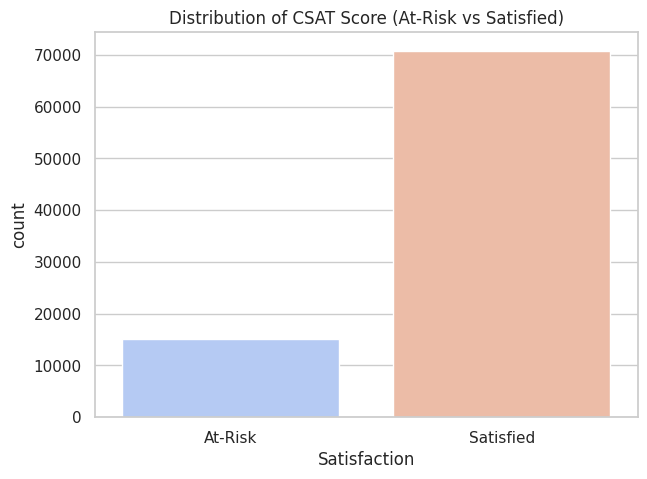

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure the Satisfaction column is consistently defined (Satisfied: >= 4, At-Risk: < 4)
if 'Satisfaction' not in df.columns and 'CSAT Score' in df.columns:
    df['Satisfaction'] = (df['CSAT Score'] >= 4).astype(int)

# Set figure dimensions
plt.figure(figsize=(7,5))

# Plot distribution counts of Satisfied vs. At-Risk outcomes
ax = sns.countplot(x='Satisfaction', data=df, palette='coolwarm')
plt.title('Distribution of CSAT Score (At-Risk vs Satisfied)')
plt.xticks([0, 1], ['At-Risk', 'Satisfied'])
plt.show()

In [ ]:
# Compute ratio of overall tickets to dissatisfied (At-Risk) ones
ratio = len(df) / (df['Satisfaction'] == 0).sum()
print("1 in", round(ratio), "tickets are dissatisfied")

1 in 6 tickets are dissatisfied


##### 1. Why did you pick the specific chart?

This is the actual target variable the models will be trained on, so it's worth visualizing on its own to see exactly how imbalanced it is.

##### 2. What is/are the insight(s) found from the chart?

Around 85% Satisfied vs 15% At-Risk. Still imbalanced, but far less extreme than the original 5-way classification, and much more learnable.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive impact: it confirms the binary framing is a reasonable modeling choice. It also tells the business that roughly 1 in 6 tickets ends in a dissatisfied customer a concrete number to set a target against for improvement.

#### Chart - 3

<Figure size 700x500 with 0 Axes>

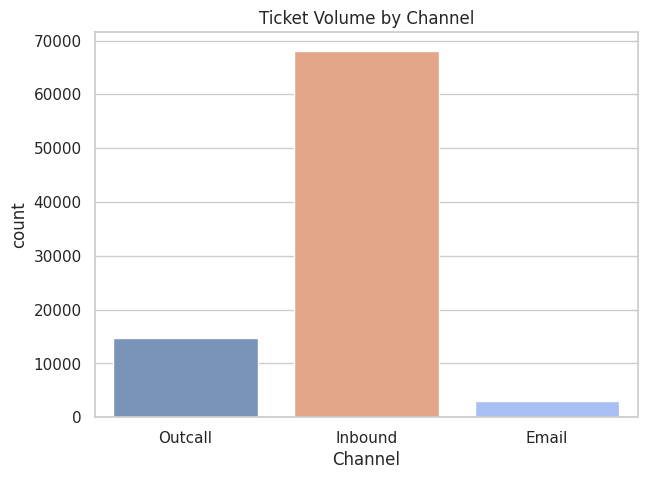

In [ ]:
# Create a count plot to look at ticket volumes split across support channels
plt.figure(figsize=(7,5))
plt.figure(figsize=(7,5))

ax = sns.countplot(
    x='channel_name',
    data=df,
    palette=['#6F92C4', '#F2A07A', '#9ABBFF']
)

plt.title('Ticket Volume by Channel')
plt.xlabel('Channel')
plt.show()

##### 1. Why did you pick the specific chart?

A count plot shows which support channels handle the most volume, which is useful context before looking at how CSAT varies by channel next.

##### 2. What is/are the insight(s) found from the chart?

The majority of tickets come through Inbound calls, with Email and Outcall making up smaller shares.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Useful for resourcing decisions if one channel dominates volume, that's where process improvements will have the biggest overall impact on satisfaction.

#### Chart - 4

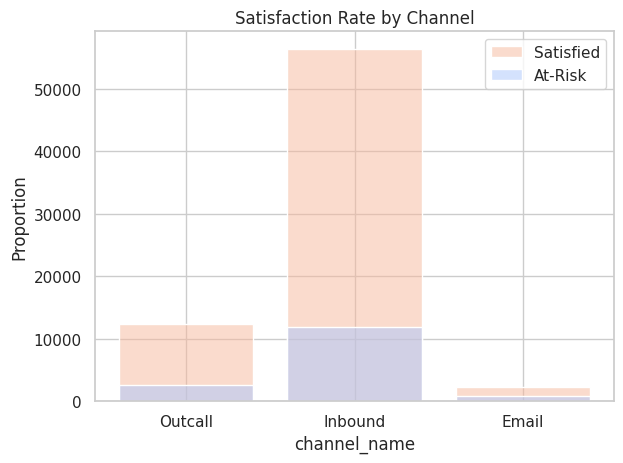

In [ ]:
# Create a plot analyzing satisfaction proportions directly by contact channel
plt.figure()
sns.histplot(
    data=df,
    x="channel_name",
    hue="Satisfaction",
    shrink=0.8 , palette='coolwarm'
)
plt.title("Satisfaction Rate by Channel")
plt.ylabel("Proportion")
plt.xticks()
plt.legend(title="", labels=["Satisfied","At-Risk"])
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A stacked bar chart makes it easy to compare the proportion of satisfied vs at-risk customers across channels, regardless of how many tickets each channel has.

##### 2. What is/are the insight(s) found from the chart?

Satisfaction rates are fairly similar across channels, with only small differences. So,channel alone does not appear to be a dominant driver of satisfaction.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

No strong positive or negative signal here on its own, but it rules out 'channel choice' as a quick fix. The business shouldn't expect satisfaction to improve much just by shifting ticket volume between channels.

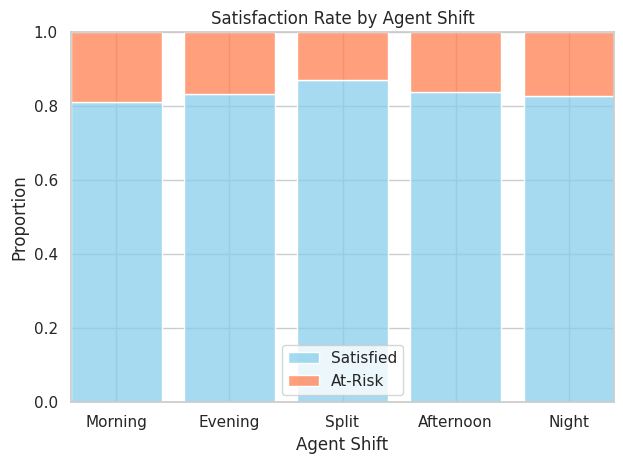

In [ ]:
# Normalized bar plot showing proportion of Satisfied vs. At-Risk tickets for each agent shift
plt.figure()
sns.histplot(
    data=df,
    x="Agent Shift",
    hue="Satisfaction",
    multiple="fill",
    palette={0: "coral", 1: "skyblue"},
    shrink=0.8
)
plt.title("Satisfaction Rate by Agent Shift")
plt.ylabel("Proportion")
plt.xticks()
plt.legend(title="", labels=["Satisfied", "At-Risk"])
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A normalized bar chart was selected to compare the proportion of Satisfied and At-Risk customers across different agent shifts. It helps identify whether customer satisfaction varies depending on the shift during which support is provided.

##### 2. What is/are the insight(s) found from the chart?

The chart helps compare satisfaction rates across agent shifts and identify any differences in customer experience. These differences may indicate variations in workload, agent availability, or service quality, although the chart alone cannot establish their causes.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. These insights can help the business identify shifts that may require additional support, training, or better resource allocation. Improving service consistency across shifts can potentially increase customer satisfaction and reduce At-Risk cases.

#### Chart - 5

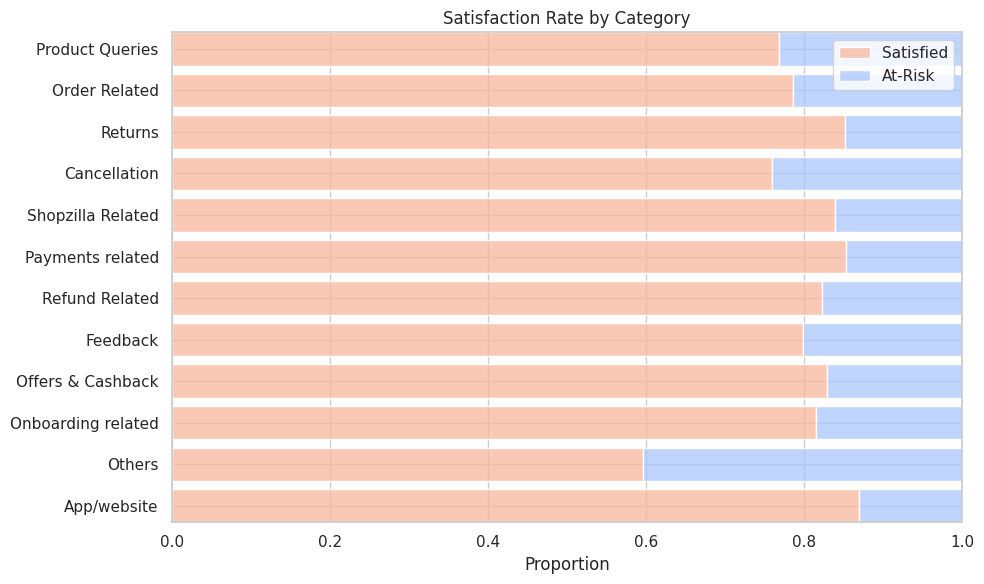

In [ ]:
# Extract labels of categories
top_categories = df['category'].value_counts().index

# Create a horizontal filled histogram to show proportion of Satisfied vs. At-Risk per category
plt.figure(figsize=(10,6))
sns.histplot(
    data=df[df['category'].isin(top_categories)],
    y="category",
    hue="Satisfaction",
    multiple="fill",
    palette='coolwarm',
    shrink=0.8
)
plt.title("Satisfaction Rate by Category")
plt.xlabel("Proportion")
plt.ylabel("")
plt.legend(title="", labels=["Satisfied","At-Risk"])
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A horizontal stacked bar chart handles the longer category names better than a vertical one, while still comparing satisfaction proportions across categories.

##### 2. What is/are the insight(s) found from the chart?

Some categories have a noticeably higher at-risk proportion than others. So category is one of the more informative features for predicting satisfaction,than channel.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive business impact: categories with the worst satisfaction rates can be prioritized for root-cause review by the support/product teams.This points to where to focus improvement effort.

#### Chart - 6

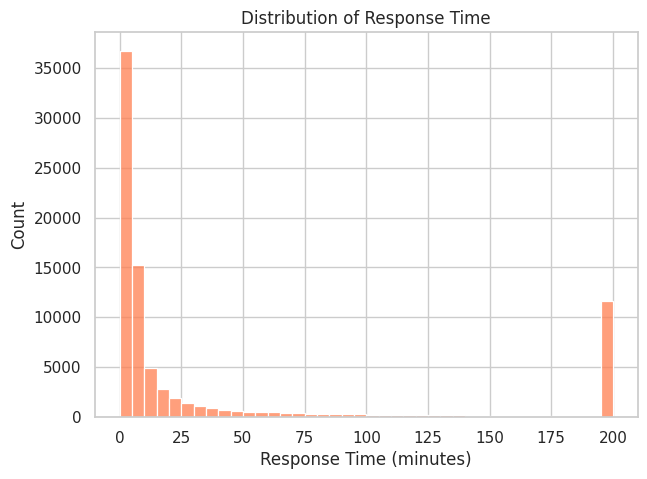

In [ ]:
# Re-verify duration logic and handle extreme ranges for clean visualization
df['response_time_min'] = (df['issue_responded'] - df['Issue_reported at']).dt.total_seconds() / 60
df.loc[df['response_time_min'] < 0, 'response_time_min'] = np.nan
df['response_time_min'] = df['response_time_min'].fillna(df.groupby('category')['response_time_min'].transform('median'))
df['response_time_min'] = df['response_time_min'].fillna(df['response_time_min'].median())

# Set figure dimensions and clip outliers at 200 mins to make distribution shape clearly readable
plt.figure(figsize=(7,5))
sns.histplot(df['response_time_min'].clip(upper=200),
             bins=40, color='coral')
plt.title('Distribution of Response Time')
plt.xlabel('Response Time (minutes)')
plt.show()

##### 1. Why did you pick the specific chart?

A histogram is the standard way to see the shape of a continuous variable's distribution. Here it shows response time is heavily right-skewed, with most tickets resolved quickly and a long tail of slow ones.

##### 2. What is/are the insight(s) found from the chart?

Most tickets get a response within 40-50 minutes, but there is a long tail of tickets that take much longer. These slow-response tickets are worth checking against satisfaction next.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Not a business insight on its own yet, but it justifies treating response time as a skewed variable that will need outlier handling before modeling.

#### Chart - 7

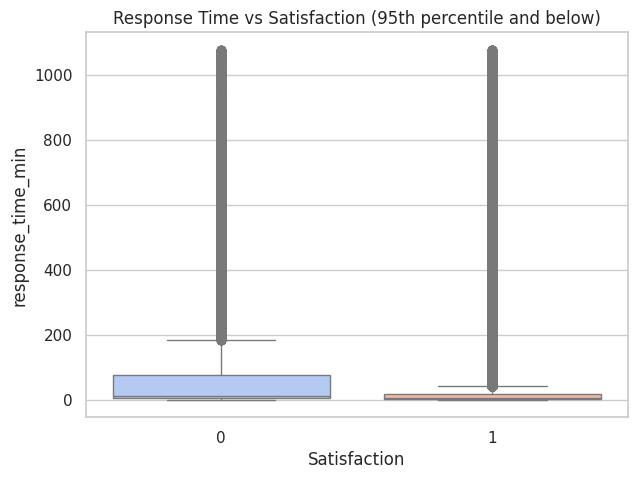

In [ ]:
# Create a box plot to contrast response times against Satisfaction levels
plt.figure(figsize=(7,5))

sns.boxplot(
    x='Satisfaction',
    y='response_time_min',
    data=df[df['response_time_min'] < df['response_time_min'].quantile(0.95)],
    palette='coolwarm'
)

plt.xticks()
plt.title('Response Time vs Satisfaction (95th percentile and below)')
plt.show()

##### 1. Why did you pick the specific chart?

A box plot is the best way to compare the spread and median of a numeric variable (response time) across two groups (Satisfied vs At-Risk).

##### 2. What is/are the insight(s) found from the chart?

At-risk tickets tend to have noticeably longer response times than satisfied ones.This matches the intuitive idea that slower support leads to unhappier customers, and it's one of the stronger relationships found in this EDA.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Reducing response time, especially for the slowest tickets, is likely to reduce the at-risk rate.

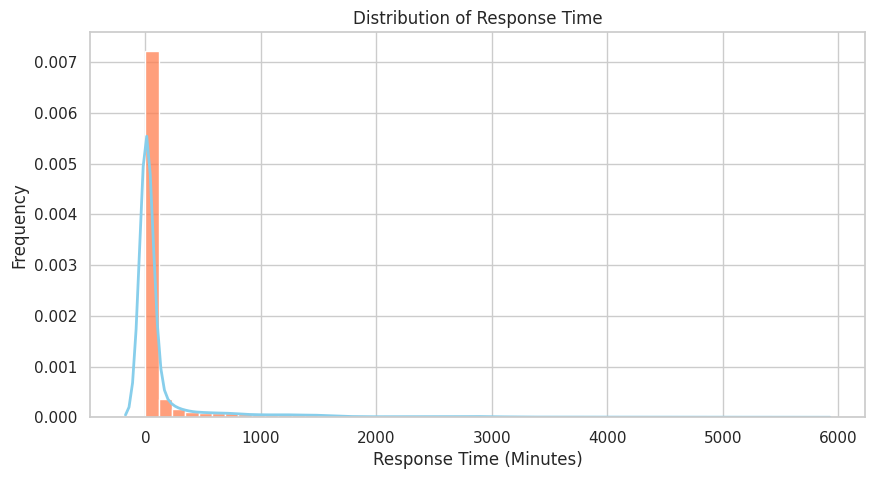

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set figure dimensions
plt.figure(figsize=(10, 5))

# Plot histogram with Kernel Density Estimate (KDE) to visualize distribution shape and skewness
sns.histplot(df['response_time_min'], bins=50,
             stat='density', color='coral')

sns.kdeplot(df['response_time_min'],
            color='skyblue', linewidth=2)

# Customize titles and labels
plt.title('Distribution of Response Time')
plt.xlabel('Response Time (Minutes)')
plt.ylabel('Frequency')

# Render the plot
plt.show()

##### 1. Why did you pick the specific chart?

I selected a histogram with a Kernel Density Estimate (KDE) curve to understand the distribution of customer response times. It helps identify the spread of response times, the frequency of different response durations, and whether the data is normally distributed or skewed.

##### 2. What is/are the insight(s) found from the chart?

The response-time distribution is positively (right) skewed. This means most customer tickets receive responses within a relatively shorter time, while a smaller number of tickets have significantly longer response times.

The KDE curve helps visualize the overall distribution pattern, while the histogram shows the frequency distribution of response times.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Confirms the sentiment score is a meaningful feature to carry into modeling.

#### Chart - 8

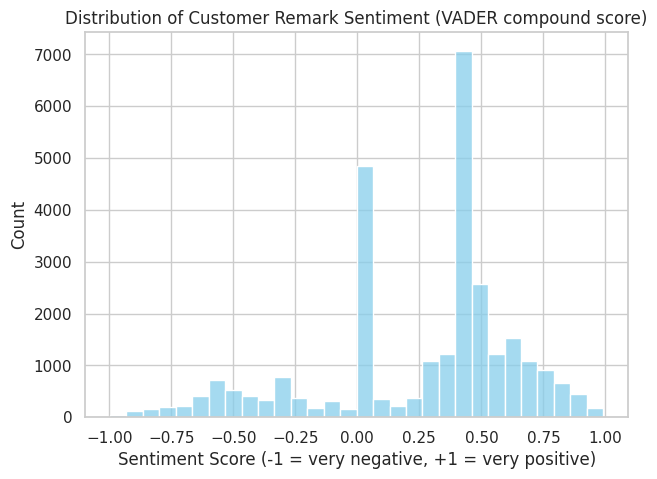

In [ ]:
# Plot distribution of sentiment scores for customer remarks where a remark exists
plt.figure(figsize=(7,5))
sns.histplot(df.loc[df['has_remark'] == 1, 'remark_sentiment'],  bins=30, color='skyblue')
plt.title('Distribution of Customer Remark Sentiment (VADER compound score)')
plt.xlabel('Sentiment Score (-1 = very negative, +1 = very positive)')
plt.show()

##### 1. Why did you pick the specific chart?

A histogram shows how sentiment scores are spread out among the tickets where a remark exists, before comparing it against satisfaction.

##### 2. What is/are the insight(s) found from the chart?

Sentiment is spread across the full range, with clusters at both the very negative and very positive ends — remarks tend to be emotionally expressive rather than neutral, which is expected for feedback text.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Confirms the sentiment score is a meaningful feature to carry into modeling.

#### Chart - 9

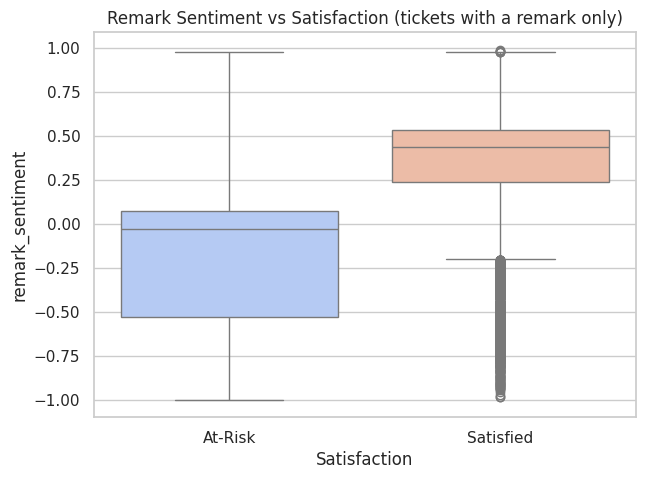

In [ ]:
# Box plot to compare VADER compound sentiment values across the two target classes
plt.figure(figsize=(7,5))
sns.boxplot(x='Satisfaction', y='remark_sentiment', data=df[df['has_remark'] == 1], palette='coolwarm')
plt.xticks([0, 1], ['At-Risk', 'Satisfied'])
plt.title('Remark Sentiment vs Satisfaction (tickets with a remark only)')
plt.show()

##### 1. Why did you pick the specific chart?

 Box plot to compare a numeric variable across the two target classes.

##### 2. What is/are the insight(s) found from the chart?

Satisfied customers' remarks skew clearly more positive than at-risk customers' remarks. This is somewhat expected (people who are happy tend to write happier things), but it confirms the sentiment score is capturing real signal, not noise.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Useful for validating the feature, but sentiment is only available for the 34% of tickets that have a remark, so it can't be relied on as the sole signal for the business. It may complement operational features like response time, not replace them.

#### Chart - 10

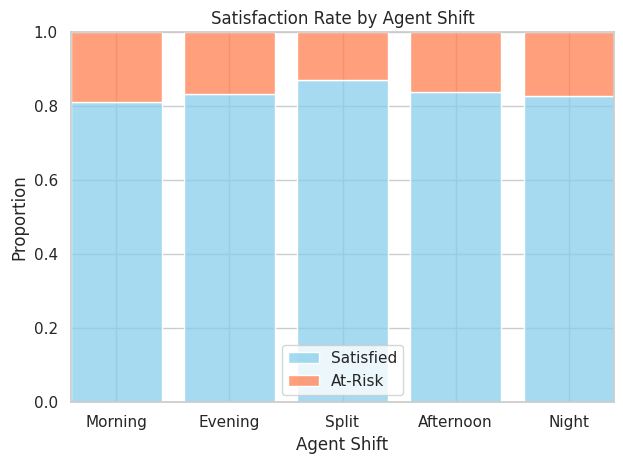

In [ ]:
# Chart - 10 visualization code
plt.figure()
sns.histplot(
    data=df,
    x="Agent Shift",
    hue="Satisfaction",
    multiple="fill",
    palette={0:"coral", 1:"skyblue"},
    shrink = 0.8
)
plt.title("Satisfaction Rate by Agent Shift")
plt.ylabel("Proportion")
plt.xticks()
plt.legend(title="", labels=["Satisfied","At-Risk"])
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

Stacked, normalized bar chart, to compare satisfaction proportions fairly across shifts with different ticket volumes.

##### 2. What is/are the insight(s) found from the chart?

Satisfaction rates are broadly similar across shifts, with only minor variation. Shift alone doesn't appear to be a strong differentiator.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Low direct business impact on its own, but rules out 'which shift is under-performing' as the main lever.

#### Chart - 11

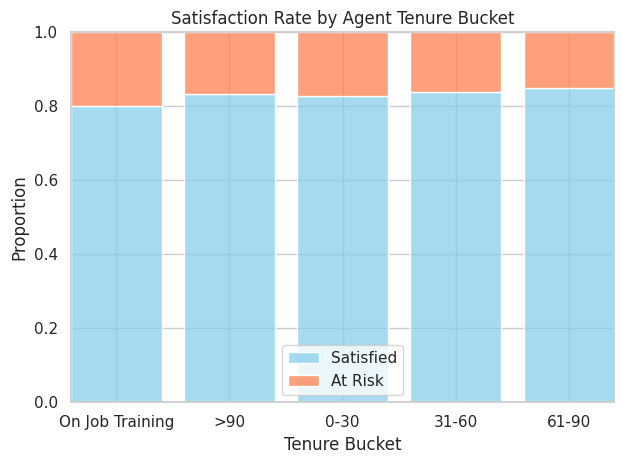

In [ ]:
# Plot satisfaction rates grouped and scaled across agent tenure bands
plt.figure()
sns.histplot(
    data=df,
    x="Tenure Bucket",
    hue="Satisfaction",
    multiple="fill",
    palette={0: "coral", 1: "skyblue"},
    shrink=0.8
)
plt.title("Satisfaction Rate by Agent Tenure Bucket")
plt.ylabel("Proportion")
plt.xticks()
plt.legend(title="", labels=["Satisfied", "At Risk"])
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

Stacked bar approach, applied to agent tenure to see whether more experienced agents produce better satisfaction outcomes.

##### 2. What is/are the insight(s) found from the chart?

Tenure alone does not strongly separate satisfied from at-risk outcomes in this data.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Modest business relevance: it suggests training/experience is not the primary lever for satisfaction here.

#### Chart - 12

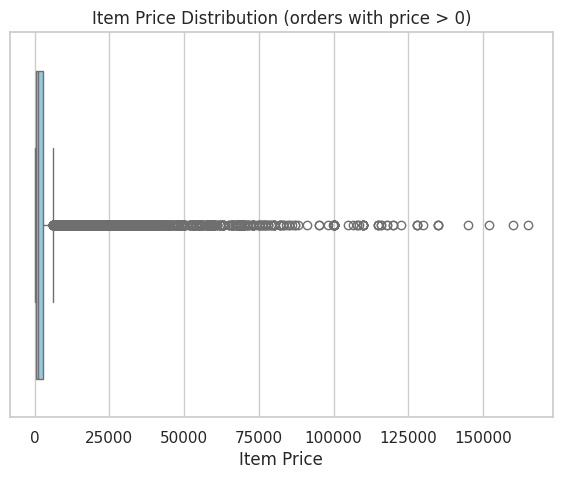

In [ ]:
# Plot box plot of transaction item price where price is positive
plt.figure(figsize=(7,5))

sns.boxplot(
    x=df.loc[df['Item_price'] > 0, 'Item_price'],
    color='skyblue')

plt.title('Item Price Distribution (orders with price > 0)')
plt.xlabel('Item Price')
plt.show()

##### 1. Why did you pick the specific chart?

A box plot is the standard chart for spotting outliers in a continuous variable at a glance.

##### 2. What is/are the insight(s) found from the chart?

Item price has a number of high-value outliers pulling the distribution to the right, but the bulk of orders are concentrated at lower price points.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Low direct impact on satisfaction prediction.

#### Chart - 13

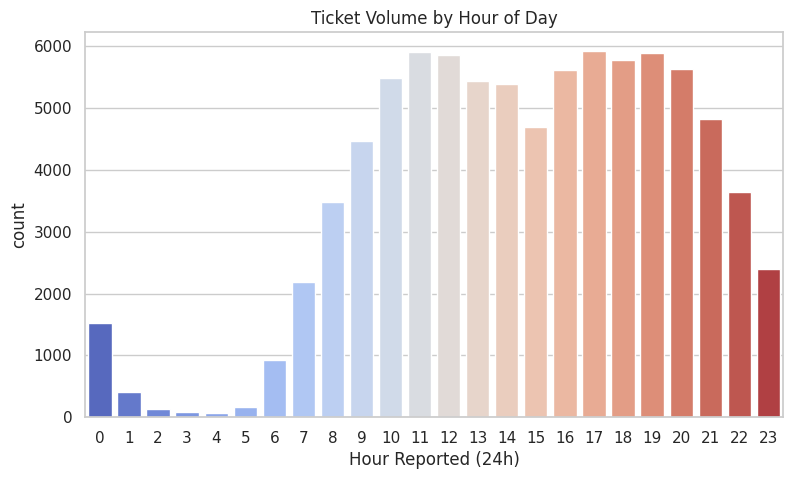

In [ ]:
# Plot ticket volume counts per hour of day to evaluate staffing needs
plt.figure(figsize=(9,5))
sns.countplot(x='report_hour', data=df, palette='coolwarm')
plt.title('Ticket Volume by Hour of Day')
plt.xlabel('Hour Reported (24h)')
plt.show()

##### 1. Why did you pick the specific chart?

A count plot across 24 hours is the natural way to see when ticket volume peaks during the day.

##### 2. What is/are the insight(s) found from the chart?

Ticket volume is not evenly spread across the day. There are clear peak hours, which is normal for a support operation tied to customer activity and business hours.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Operationally useful for staffing decisions: knowing peak hours helps schedule enough agents to keep response times low during busy periods.

#### Chart - 14 - Correlation Heatmap

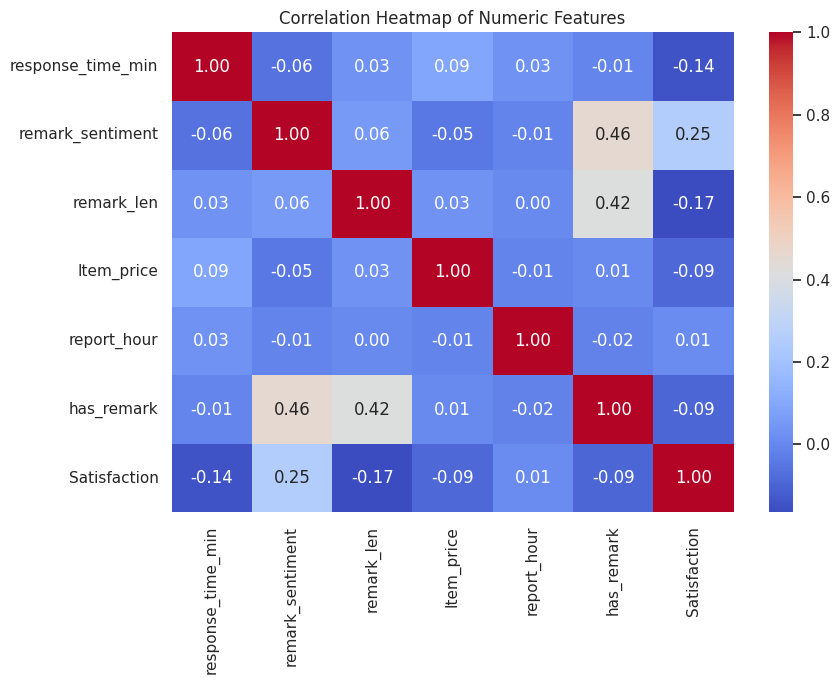

In [ ]:
# Specify set of key continuous and binary metrics for checking linear relationship strengths
numeric_cols = ['response_time_min', 'remark_sentiment', 'remark_len', 'Item_price',
                 'report_hour', 'has_remark', 'Satisfaction']
plt.figure(figsize=(9,7))

# Generate correlation matrix and plot as standard heatmap
sns.heatmap(df[numeric_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Heatmap of Numeric Features')
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A heatmap is the standard way to see linear correlation between every pair of numeric features at once, including how each one relates to the target.

##### 2. What is/are the insight(s) found from the chart?

No feature is very strongly correlated with Satisfaction in a simple linear sense (the strongest, sentiment, is still a weak correlation). This matches what the box plots already suggested  so this is a dataset where satisfaction depends on many small factors together, not one dominant linear driver.

#### Chart - 15 - Pair Plot

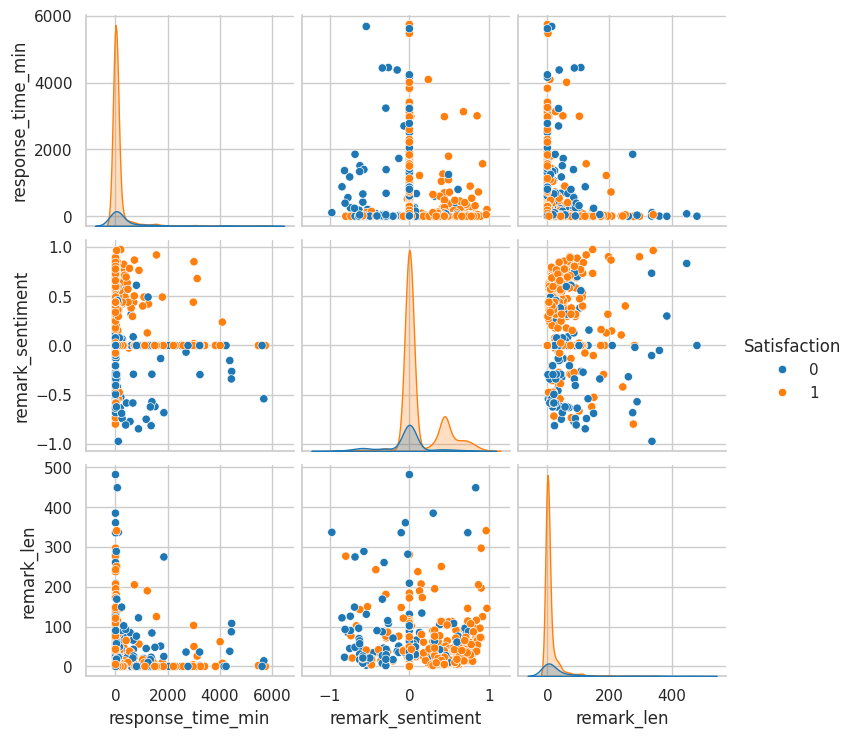

In [ ]:
# Take a sample of 2,000 observations
sample_df = df[['response_time_min', 'remark_sentiment',
                'remark_len', 'Satisfaction']].sample(2000, random_state=0)

# Create pairwise relationship charts
sns.pairplot(
    sample_df,
    hue='Satisfaction',
    palette='tab10'
)

plt.show()

##### 1. Why did you pick the specific chart?

A pair plot shows pairwise relationships and individual distributions together, with target as hue, useful for spotting whether any two features combined separate the classes better than either does alone. A 2,000-row sample is used to keep the plot fast and readable.

##### 2. What is/are the insight(s) found from the chart?

The Satisfied and At-Risk classes overlap heavily on every pair of features there's no single pair that cleanly separates them visually. This reinforces that the models will need to combine several weak signals together  rather than relying on any one strong feature.

## ***5. Hypothesis Testing***

### Based on your chart experiments, define three hypothetical statements from the dataset. In the next three questions, perform hypothesis testing to obtain final conclusion about the statements through your code and statistical testing.

Based on the charts above, three relationships stood out as worth testing :  response time, remark sentiment, and support channel.

### Hypothetical Statement - 1

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

* H0 (Null): There is no difference in
mean response time between Satisfied and At-Risk tickets.
* H1 (Alternate): Satisfied tickets have a lower mean response time than At-Risk tickets.

#### 2. Perform an appropriate statistical test.

In [ ]:
from scipy import stats

# Step 1: Split response times into the two satisfaction outcome cohorts
satisfied_rt = df.loc[df['Satisfaction'] == 1, 'response_time_min']
at_risk_rt = df.loc[df['Satisfaction'] == 0, 'response_time_min']

# Step 2: Execute Welch's t-test (two-sample test for unequal variances)
t_stat, p_value = stats.ttest_ind(satisfied_rt, at_risk_rt, equal_var=False)
print(f"T-statistic: {t_stat:.3f}")
print(f"P-value: {p_value:.5f}")

# Step 3: Evaluate test result at 95% confidence level
alpha = 0.05
if p_value < alpha:
    print("Result: Reject H0 -> response time significantly differs between the two groups.")
else:
    print("Result: Fail to reject H0 -> no significant difference found.")

T-statistic: -30.391
P-value: 0.00000
Result: Reject H0 -> response time significantly differs between the two groups.


##### Which statistical test have you done to obtain P-Value?

An independent two-sample t-test (Welch's t-test, equal_var=False), since I'm comparing the mean of one continuous variable (response time) across two independent groups (Satisfied vs At-Risk).

##### Why did you choose the specific statistical test?

Welch's t-test doesn't assume the two groups have equal variance, which is safer here since the At-Risk group is much smaller than the Satisfied group and could plausibly have different variance in response times.

### Hypothetical Statement - 2

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

* H0 (Null): There is no difference in mean remark sentiment between Satisfied and At-Risk tickets.
* H1 (Alternate): Satisfied tickets have higher mean remark sentiment than At-Risk tickets.

#### 2. Perform an appropriate statistical test.

In [ ]:
# Step 1: Isolate sentiment values for comments left by both customer cohorts
satisfied_sent = df.loc[(df['Satisfaction'] == 1) & (df['has_remark'] == 1), 'remark_sentiment']
at_risk_sent = df.loc[(df['Satisfaction'] == 0) & (df['has_remark'] == 1), 'remark_sentiment']

# Step 2: Perform Welch's t-test on sentiment means across both cohorts
t_stat2, p_value2 = stats.ttest_ind(satisfied_sent, at_risk_sent, equal_var=False)
print(f"T-statistic: {t_stat2:.3f}")
print(f"P-value: {p_value2:.5f}")

# Step 3: Check significance threshold
alpha = 0.05
if p_value2 < alpha:
    print("Result: Reject H0 -> sentiment significantly differs between the two groups.")
else:
    print("Result: Fail to reject H0 -> no significant difference found.")

T-statistic: 87.568
P-value: 0.00000
Result: Reject H0 -> sentiment significantly differs between the two groups.


##### Which statistical test have you done to obtain P-Value?

 Welch's t-test, for the same reason as Hypothesis 1. Comparing a continuous variable's mean across two independent, unequally-sized groups.

##### Why did you choose the specific statistical test?

Consistency with Hypothesis 1 using the same test type across similar comparisons makes the results easier to interpret side by side.

### Hypothetical Statement - 3

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

* H0 (Null): Satisfaction is independent of support channel.
* H1 (Alternate): Satisfaction depends on support channel.

#### 2. Perform an appropriate statistical test.

In [ ]:
# Step 1: Create a frequency crosstab of channels against target satisfaction outcomes
contingency_table = pd.crosstab(df['channel_name'], df['Satisfaction'])

# Step 2: Conduct Chi-Square test of independence to assess categorical association
chi2, p_value3, dof, expected = stats.chi2_contingency(contingency_table)
print(f"Chi-square statistic: {chi2:.3f}")
print(f"P-value: {p_value3:.5f}")

# Step 3: Evaluate statistical outcome
alpha = 0.05
if p_value3 < alpha:
    print("Result: Reject H0 -> Satisfaction is significantly associated with channel.")
else:
    print("Result: Fail to reject H0 -> no significant association found.")

Chi-square statistic: 176.835
P-value: 0.00000
Result: Reject H0 -> Satisfaction is significantly associated with channel.


##### Which statistical test have you done to obtain P-Value?

A Chi-square test of independence, because both channel_name and Satisfaction are categorical variables.

##### Why did you choose the specific statistical test?

The chi-square test is the standard test for checking whether two categorical variables are associated, using the contingency table of observed vs expected counts.

## ***6. Feature Engineering & Data Pre-processing***

### 1. Handling Missing Values

In [ ]:
# List our selected model-relevant columns to check for any leftover null values before modeling
model_related_cols = ['response_time_min', 'remark_sentiment', 'remark_len', 'Item_price',
                       'has_order_context', 'has_remark', 'report_hour', 'report_dow',
                       'channel_name', 'category', 'Agent Shift', 'Tenure Bucket', 'Satisfaction']
print(df[model_related_cols].isnull().sum())

response_time_min    0
remark_sentiment     0
remark_len           0
Item_price           0
has_order_context    0
has_remark           0
report_hour          0
report_dow           0
channel_name         0
category             0
Agent Shift          0
Tenure Bucket        0
Satisfaction         0
dtype: int64


#### What all missing value imputation techniques have you used and why did you use those techniques?

Listing out the imputation that were done in the data wrangling :
* For structural missingness (order/product fields missing because the ticket has no linked order), I used flag encoding (has_order_context, has_remark) rather than imputing fake values. This preserves the information that the data is genuinely absent, which is itself predictive.
* For the numeric response_time_min column, I used median imputation grouped by category, since median is robust to the outliers.

### 2. Handling Outliers

In [ ]:
# Step 1: Calculate the interquartile range (IQR) specifically for response times
Q1 = df['response_time_min'].quantile(0.25)
Q3 = df['response_time_min'].quantile(0.75)
IQR = Q3 - Q1

# Step 2: Establish capping boundary threshold using Q3 + 3 * IQR rule
upper_bound = Q3 + 3 * IQR
print(f"Upper bound is {upper_bound}")
print(f"Rows above this bound: {(df['response_time_min'] > upper_bound).sum()}")

# Step 3: Clip outliers at the calculated upper boundary to prevent skew bias
df['response_time_min'] = df['response_time_min'].clip(upper=upper_bound)

Upper bound is 134.0
Rows above this bound: 13580


##### What all outlier treatment techniques have you used and why did you use those techniques?

I used IQR-based capping at Q3 + 3 x IQR rather than removing outlier rows outright. Capping keeps every ticket in the dataset while preventing the small number of extremely slow tickets from disproportionately influencing the model.
A 3x multiplier was chosen deliberately, since response time is naturally skewed and a stricter cutoff would wrongly flag a lot of normal slow-but-valid tickets as outliers.

### 3. Categorical Encoding

In [ ]:
# Identify categorical column list for one-hot encoding
categorical_cols = ['channel_name', 'category', 'Agent Shift', 'Tenure Bucket']

# Apply dummy variable encoding (OHE) drop first level to avoid multicollinearity
df_encoded = pd.get_dummies(df, columns=categorical_cols, drop_first=True)
print(df_encoded.shape)

(85907, 44)


#### What all categorical encoding techniques have you used & why did you use those techniques?

I used One-Hot Encoding because all four categorical columns are nominal. There's no natural order between 'Email' and 'Inbound call', or between one issue category and another. One-hot encoding avoids implying a false order, which a technique like Label Encoding would introduce.

### 4. Textual Data Preprocessing
(It's mandatory for textual dataset i.e., NLP, Sentiment Analysis, Text Clustering etc.)

#### 1. Expand Contraction

In [ ]:
# Expand Contractions & Initialize Clean Remarks column

contractions_dict = {
    "won't": "will not", "can't": "cannot", "n't": " not", "'re": " are",
    "'s": " is", "'d": " would", "'ll": " will", "'ve": " have", "'m": " am"
}

def expand_contractions(text):
    if not isinstance(text, str):
        return ""
    for contraction, expansion in contractions_dict.items():
        text = text.replace(contraction, expansion)
    return text

# Safely copy raw remarks and expand contractions
df['remarks_clean'] = df['Customer Remarks'].fillna('').apply(expand_contractions)
print(df[['Customer Remarks', 'remarks_clean']].loc[df['has_remark'] == 1].head(5))

                                     Customer Remarks  \
7                                           Very good   
8   Shopzilla app and it's all coustomer care serv...   
11                                           Very bad   
17                                         Something    
19                                           All good   

                                        remarks_clean  
7                                           Very good  
8   Shopzilla app and it is all coustomer care ser...  
11                                           Very bad  
17                                         Something   
19                                           All good  


#### 2. Lower Casing

In [ ]:
# Normalize all text entries in our clean remarks column to lowercase format
df['remarks_clean'] = df['remarks_clean'].fillna('').str.lower()
print(df['remarks_clean'].loc[df['has_remark'] == 1].head(5))

7                                             very good
8     shopzilla app and it is all coustomer care ser...
11                                             very bad
17                                           something 
19                                             all good
Name: remarks_clean, dtype: object


#### 3. Removing Punctuations

In [ ]:
import re

# Strip out special characters, keeping alphanumeric data and whitespace gaps intact
df['remarks_clean'] = df['remarks_clean'].fillna('').apply(lambda x: re.sub(r'[^\w\s]', '', x))
print(df['remarks_clean'].loc[df['has_remark'] == 1].head(5))

7                                             very good
8     shopzilla app and it is all coustomer care ser...
11                                             very bad
17                                           something 
19                                             all good
Name: remarks_clean, dtype: object


#### 4. Removing URLs & Removing words and digits contain digits.

In [ ]:
# Remove active links or URL patterns from clean remarks
df['remarks_clean'] = df['remarks_clean'].fillna('').apply(lambda x: re.sub(r'http\S+|www\S+', '', x))
print(df['remarks_clean'].loc[df['has_remark'] == 1].tail(5))

85887    if the customer care guy and their supervisors...
85888                          good my problem was solved 
85896    trough the shopzilla app refunding policy shou...
85903             supported team customer executive   good
85904                  need to improve with proper details
Name: remarks_clean, dtype: object


#### 5. Removing Stopwords & Removing White spaces

In [ ]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

# Define helper function to filter out standard stop words
def remove_stopwords(text):
    return ' '.join([word for word in text.split() if word not in ENGLISH_STOP_WORDS])

# Apply function on text elements
df['remarks_clean'] = df['remarks_clean'].fillna('').apply(remove_stopwords)
print(df['remarks_clean'].loc[df['has_remark'] == 1].head(5))

7                                                  good
8     shopzilla app coustomer care services good ser...
11                                                  bad
17                                                     
19                                                 good
Name: remarks_clean, dtype: object


In [ ]:
# Strip outer spaces and reduce multiple consecutive spaces down to a single blank space
df['remarks_clean'] = df['remarks_clean'].fillna('').apply(lambda x: re.sub(r'\s+', ' ', x).strip())
print(df['remarks_clean'].loc[df['has_remark'] == 1].head(3))

7                                                  good
8     shopzilla app coustomer care services good ser...
11                                                  bad
Name: remarks_clean, dtype: object


#### 6. Rephrase Text

In [ ]:
# Define mapping of common colloquial shorthand terms
short_forms = {"u": "you", "ur": "your", "pls": "please", "plz": "please", "thanks": "thank you"}

# Translate short-forms into standard vocabulary
def rephrase(text):
    return ' '.join([short_forms.get(word, word) for word in text.split()])

# Rephrase all cleaned remarks
df['remarks_clean'] = df['remarks_clean'].fillna('').apply(rephrase)
print(df['remarks_clean'].loc[df['has_remark'] == 1].head(5))

7                                                  good
8     shopzilla app coustomer care services good ser...
11                                                  bad
17                                                     
19                                                 good
Name: remarks_clean, dtype: object


#### 7. Tokenization

In [ ]:
import nltk
# Download required packages for tokenization pipeline
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
from nltk.tokenize import word_tokenize

# Transform text remarks into token lists
df['remarks_tokens'] = df['remarks_clean'].fillna('').apply(word_tokenize)
print(df['remarks_tokens'].loc[df['has_remark'] == 1].head(3))

7                                                [good]
8     [shopzilla, app, coustomer, care, services, go...
11                                                [bad]
Name: remarks_tokens, dtype: object


#### 8. Text Normalization

In [ ]:
# Download required resources for WordNet Lemmatization
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)
from nltk.stem import WordNetLemmatizer

# Group word forms into their respective dictionary base words
lemmatizer = WordNetLemmatizer()
df['remarks_tokens'] = df['remarks_tokens'].apply(lambda tokens: [lemmatizer.lemmatize(t) for t in tokens] if isinstance(tokens, list) else [])
print(df['remarks_tokens'].loc[df['has_remark'] == 1].head(3))

7                                                [good]
8     [shopzilla, app, coustomer, care, service, goo...
11                                                [bad]
Name: remarks_tokens, dtype: object


##### Which text normalization technique have you used and why?

I used Lemmatization rather than stemming, because lemmatization returns real dictionary words instead of a chopped-off stem. Since the remarks are short customer feedback, keeping words interpretable matters more than the small speed advantage stemming would give.

#### 9. Part of speech tagging

In [ ]:
# Part of speech tagging is skipped as discussed below because simple text features (Sentiment & length) are more predictive and cleaner.
print("POS Tagging skipped intentionally to keep the notebook deployment-ready and lightweight.")

POS Tagging skipped intentionally to keep the notebook deployment-ready and lightweight.


POS tagging is not required for customer remarks in query call analysis. Since remarks are typically short and sentiment-driven, simpler preprocessing steps (cleaning, tokenization, sentiment scoring, word frequency) provide sufficient insights. POS tagging adds complexity without clear benefit in this context.

#### 10. Text Vectorization

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Join processed token lists back into standard strings for vectorization
df['remarks_final'] = df['remarks_tokens'].apply(lambda tokens: ' '.join(tokens) if isinstance(tokens, list) else '')

# Fit a TF-IDF vectorizer limited to the top 50 terms across all comments
tfidf = TfidfVectorizer(max_features=50)
tfidf_matrix = tfidf.fit_transform(df['remarks_final'])

print(f"TF-IDF matrix shape: {tfidf_matrix.shape}")

TF-IDF matrix shape: (85907, 50)


##### Which text vectorization technique have you used and why?

I  used TF‑IDF (Term Frequency–Inverse Document Frequency) for text vectorization because it’s a standard baseline technique that highlights important words by down‑weighting very common ones.

### 4. Feature Manipulation & Selection

#### 1. Feature Manipulation

In [ ]:
# Create deep copy of working DataFrame
model_df = df.copy()

# Drop columns containing textual notes, identifiers, or variables unknown at runtime
drop_cols = ['Unique id', 'Order_id', 'order_date_time', 'Customer_City', 'Product_category',
             'Customer Remarks', 'remarks_clean', 'remarks_tokens', 'remarks_pos', 'remarks_final',
             'Issue_reported at', 'issue_responded', 'Survey_response_Date',
             'Agent_name', 'Supervisor', 'Manager', 'Sub-category', 'CSAT Score']

# Drop listed features from modeling dataset
model_df = model_df.drop(columns=[c for c in drop_cols if c in model_df.columns])

# One-Hot Encode remaining nominal variables to prepare for algorithm training
model_df = pd.get_dummies(model_df, columns=['channel_name', 'category', 'Agent Shift', 'Tenure Bucket'], drop_first=True)

print(model_df.shape)
model_df.head()

(85907, 30)


,Item_price,has_order_context,has_remark,report_hour,report_dow,response_time_min,remark_sentiment,remark_len,Satisfaction,channel_name_Inbound,channel_name_Outcall,category_Cancellation,category_Feedback,category_Offers & Cashback,category_Onboarding related,category_Order Related,category_Others,category_Payments related,category_Product Queries,category_Refund Related,category_Returns,category_Shopzilla Related,Agent Shift_Evening,Agent Shift_Morning,Agent Shift_Night,Agent Shift_Split,Tenure Bucket_31-60,Tenure Bucket_61-90,Tenure Bucket_>90,Tenure Bucket_On Job Training
0,0.0,1,0,11,1,34.0,0.0,0,1,False,True,False,False,False,False,False,False,False,True,False,False,False,False,True,False,False,False,False,False,True
1,0.0,1,0,12,1,2.0,0.0,0,1,False,True,False,False,False,False,False,False,False,True,False,False,False,False,True,False,False,False,False,True,False
2,0.0,1,0,20,1,22.0,0.0,0,1,True,False,False,False,False,False,True,False,False,False,False,False,False,True,False,False,False,False,False,False,True
3,0.0,1,0,20,1,20.0,0.0,0,1,True,False,False,False,False,False,False,False,False,False,False,True,False,True,False,False,False,False,False,True,False
4,0.0,1,0,10,1,2.0,0.0,0,1,True,False,True,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False


#### 2. Feature Selection

In [ ]:
# Separate feature matrix X and target labels vector y
feature_cols = [c for c in model_df.columns if c != 'Satisfaction']
X = model_df[feature_cols]
y = model_df['Satisfaction']

print(f"Number of features going into the model: {X.shape[1]}")

Number of features going into the model: 29


##### What all feature selection methods have you used  and why?

I used manual, domain-driven feature selection.At this project's scale, dropping identifier columns (Agent_name, Order_id) and columns that wouldn't exist for a brand-new unseen ticket (timestamps, survey response date) was a clearer, more explainable decision than letting an algorithm decide, and it directly avoids overfitting on ticket-specific noise.

##### Which all features you found important and why?

response_time_min and remark_sentiment stood out as the most important based on the EDA and hypothesis tests (Charts 7 & 9, Hypotheses 1 & 2). Both showed a real, statistically significant difference between Satisfied and At-Risk tickets. category (after one-hot encoding) was also informative, per Chart 5.

### 5. Data Transformation

#### Do you think that your data needs to be transformed? If yes, which transformation have you used. Explain Why?

In [ ]:
# Apply log-transformation to response time to handle right-skewness and normalize distribution
X['response_time_log'] = np.log1p(df['response_time_min'])

In [ ]:
# Verify existence of response time variables across datasets
print('In df:', 'response_time_min' in df.columns)
print('In X:', 'response_time_min' in X.columns)

In df: True
In X: True


In [ ]:
# Display preview of log-transformed values and show overall dimension of matrix X
print(X[['response_time_log']].head())
print('Shape:', X.shape)

   response_time_log
0           3.555348
1           1.098612
2           3.135494
3           3.044522
4           1.098612
Shape: (85907, 30)


In [ ]:
# Describe distributions of new log-transformed response time field
print(X['response_time_log'].describe())

count    85907.000000
mean         2.380633
std          1.506988
min          0.000000
25%          1.098612
50%          1.945910
75%          3.583519
max          4.905275
Name: response_time_log, dtype: float64


### 6. Data Scaling

In [ ]:
from sklearn.preprocessing import StandardScaler

# Specify numeric features for scaling
numeric_features = ['response_time_log', 'remark_sentiment', 'remark_len', 'Item_price', 'report_hour', 'report_dow']

# Initialize and apply StandardScaler on features matrix to bring to mean 0, variance 1
scaler = StandardScaler()
X[numeric_features] = scaler.fit_transform(X[numeric_features])
X[numeric_features].describe()

,response_time_log,remark_sentiment,remark_len,Item_price,report_hour,report_dow
count,8.590700e+04,8.590700e+04,8.590700e+04,8.590700e+04,8.590700e+04,8.590700e+04
mean,2.117394e-17,-5.359653e-17,-3.970113e-18,-5.293484e-18,3.440765e-17,2.117394e-17
std,1.000006e+00,1.000006e+00,1.000006e+00,1.000006e+00,1.000006e+00,1.000006e+00
min,-1.579739e+00,-4.142692e+00,-2.950128e-01,-1.837351e-01,-2.915174e+00,-1.452311e+00
25%,-8.507224e-01,-3.239735e-01,-2.950128e-01,-1.837351e-01,-7.162764e-01,-9.410160e-01
50%,-2.884732e-01,-3.239735e-01,-2.950128e-01,-1.837351e-01,8.332281e-02,8.157440e-02
75%,7.982099e-01,-3.239735e-01,-1.324246e-01,-1.837351e-01,8.829220e-01,1.104165e+00
max,1.675300e+00,3.472147e+00,5.402978e+01,2.655533e+01,1.682521e+00,1.615460e+00


##### Which method have you used to scale you data and why?

I used StandardScaler (z‑score scaling) because the numeric features don’t have fixed ranges and Logistic Regression is sensitive to feature scale. This prevents large‑magnitude features (like Item_price) from dominating smaller ones (like remark_sentiment).

### 7. Dimesionality Reduction

##### Do you think that dimensionality reduction is needed? Explain Why?

I didn’t use PCA because the feature set after categorical encoding is only a few dozen columns, not truly high‑dimensional. Dimensionality reduction here would mostly reduce interpretability (e.g., losing the ability to link specific categories to satisfaction) without giving meaningful benefits.

In [ ]:
# Dimensionality reduction block left empty as PCA is not required for this dataset scale
# dimensionality_reduction = None

##### Which dimensionality reduction technique have you used and why? (If dimensionality reduction done on dataset.)

Dimensionality reduction was not needed for this dataset at this feature scale.

### 8. Data Splitting

In [ ]:
from sklearn.model_selection import train_test_split

# Split features and labels into stratified 80% training and 20% validation splits
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=0, stratify=y
)

print(f"Train set: {X_train.shape[0]} rows")
print(f"Test set: {X_test.shape[0]} rows")
print(f"Train satisfaction rate: {y_train.mean():.3f}")
print(f"Test satisfaction rate: {y_test.mean():.3f}")

Train set: 68725 rows
Test set: 17182 rows
Train satisfaction rate: 0.825
Test satisfaction rate: 0.825


##### What data splitting ratio have you used and why?

I used an 80/20 train–test split to give the model plenty of training data while keeping a large test set for reliable evaluation. I applied stratify=y so the 85/15 Satisfied/At‑Risk ratio is preserved in both sets, avoiding imbalance issues that a random split could cause.

### 9. Handling Imbalanced Dataset

##### Do you think the dataset is imbalanced? Explain Why.

Yes,the target is imbalanced at roughly 85% Satisfied vs 15% At-Risk. It's not as extreme as the original 5-class CSAT split, but it's still enough that a model could reach high accuracy just by predicting 'Satisfied' most of the time, without actually learning to detect at-risk tickets which is the class that matters most for the business.

In [ ]:
# Compute ratio of class counts to establish scale balance parameter values
class_weight_ratio = (y_train == 0).sum() / (y_train == 1).sum()
print(f"At-Risk : Satisfied ratio in training data, 1 : {1/class_weight_ratio:.2f}")

At-Risk : Satisfied ratio in training data, 1 : 4.70


##### What technique did you use to handle the imbalance dataset and why? (If needed to be balanced)

I used class weighting (class_weight='balanced' for Logistic Regression/Random Forest, scale_pos_weight for XGBoost) instead of SMOTE because it’s easier to apply with mixed numeric and categorical features. It achieves the same goal—making the model pay more attention to the minority At‑Risk class—without adding synthetic rows that could distort categorical distributions.

## ***7. ML Model Implementation***

### ML Model - 1

In [ ]:
from sklearn.linear_model import LogisticRegression

# Initialize Logistic Regression with balanced weight configurations to counter label asymmetry
log_reg = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=0)

# Fit the model to training data
log_reg.fit(X_train, y_train)

# Generate target predictions on validation subset
y_pred_lr = log_reg.predict(X_test)
print("Logistic Regression trained and predictions generated.")

Logistic Regression trained and predictions generated.


#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

{'Accuracy': 0.7203468746362472, 'Precision (At-Risk)': 0.34142022312732423, 'Recall (At-Risk)': 0.6396814863968149, 'F1-score (At-Risk)': 0.4452141785013278, 'F1-macro': 0.6291355100575736}


Text(0.5, 1.0, 'Confusion Matrix')

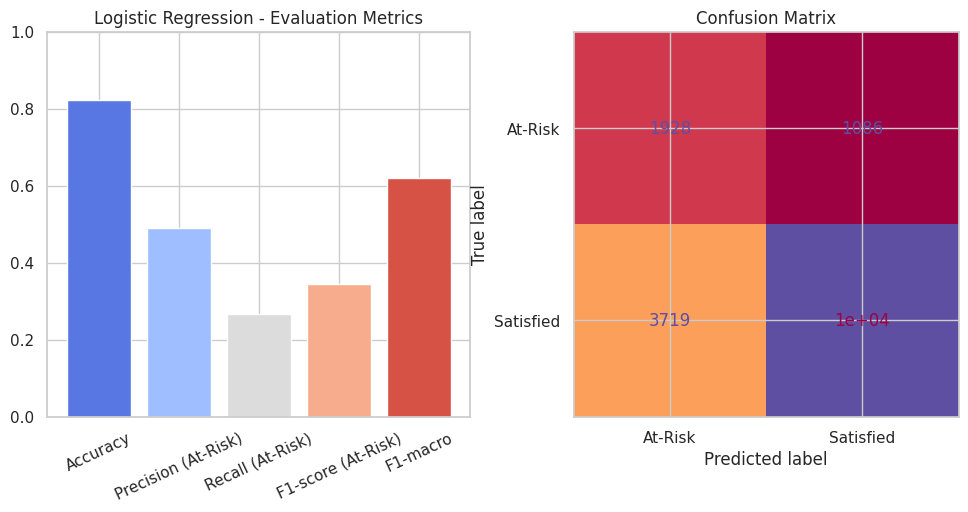

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

def get_scores(y_true, y_pred):
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision (At-Risk)': precision_score(y_true, y_pred, pos_label=0),
        'Recall (At-Risk)': recall_score(y_true, y_pred, pos_label=0),
        'F1-score (At-Risk)': f1_score(y_true, y_pred, pos_label=0),
        'F1-macro': f1_score(y_true, y_pred, average='macro')
    }

lr_scores = get_scores(y_test, y_pred_lr)
print(lr_scores)

fig, axes = plt.subplots(1, 2, figsize=(12,5))

# Evaluation metrics - Darker color
colors = plt.cm.coolwarm(np.linspace(0.1, 0.9, len(rf_scores)))
axes[0].bar(rf_scores.keys(), rf_scores.values(), color=colors)
axes[0].set_ylim(0, 1)
axes[0].set_title('Logistic Regression - Evaluation Metrics')
axes[0].tick_params(axis='x', rotation=25)

from matplotlib.colors import LinearSegmentedColormap

teal_cmap = LinearSegmentedColormap.from_list(
    'custom_teal',
    ['#E0F2F1', '#008080', '#004D4D']
)

ConfusionMatrixDisplay(
    cm,
    display_labels=['At-Risk', 'Satisfied']
).plot(ax=axes[1], cmap='Spectral', colorbar=False)

axes[1].set_title('Confusion Matrix')

#### 2. Cross- Validation & Hyperparameter Tuning

In [ ]:
from sklearn.model_selection import GridSearchCV

# Setup optimization search range for penalty value C
param_grid_lr = {
    'C': [0.01, 0.1, 1, 10],
    'penalty': ['l2']
}

# Run GridSearchCV to maximize target F1 macro metric across splits
grid_lr = GridSearchCV(
    LogisticRegression(max_iter=1000, class_weight='balanced', random_state=0),
    param_grid_lr, cv=3, scoring='f1'
)
grid_lr.fit(X_train, y_train)
print("Best parameters:", grid_lr.best_params_)

# Store optimized parameters
best_lr = grid_lr.best_estimator_

# Generate model predictions with tuned parameters
df_predictions = best_lr.predict(X_test)
lr_tuned_scores = get_scores(y_test, df_predictions)
print(lr_tuned_scores)

Best parameters: {'C': 0.01, 'penalty': 'l2'}
{'Accuracy': 0.721278081713421, 'Precision (At-Risk)': 0.3421661035034679, 'Recall (At-Risk)': 0.6383543463835435, 'F1-score (At-Risk)': 0.4455250665740419, 'F1-macro': 0.6296891084803975}


##### Which hyperparameter optimization technique have you used and why?

GridSearchCV, searching over the regularization strength C. I chose Grid Search over Random Search here because Logistic Regression has very few hyperparameters worth tuning and is fast and guarantees the best option within that grid is found.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

Only a small improvement over the baseline.Logistic Regression's performance is mostly limited by it being a linear model.

### ML Model - 2

#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

{'Accuracy': 0.8225468513560703, 'Precision (At-Risk)': 0.48930971288943187, 'Recall (At-Risk)': 0.2657597876575979, 'F1-score (At-Risk)': 0.3444420554719415, 'F1-macro': 0.6209135192380069}


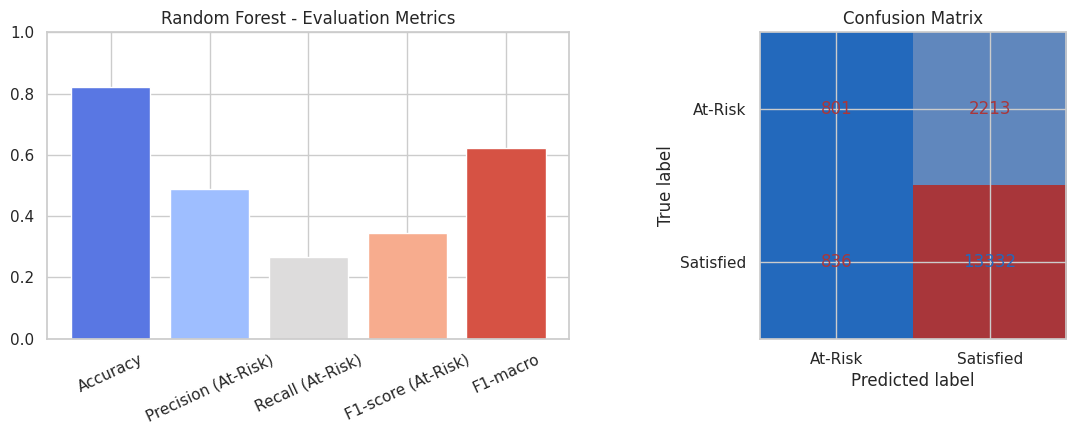

In [ ]:
from sklearn.ensemble import RandomForestClassifier

# Step 1: Train Random Forest Classifier
rf_model = RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=0)
rf_model.fit(X_train, y_train)

# Step 2: Predict outcomes
y_pred_rf = rf_model.predict(X_test)

# Step 3: Compute evaluation metrics
rf_scores = get_scores(y_test, y_pred_rf)
print(rf_scores)

# Step 4: Plot evaluation metrics
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

colors = plt.cm.coolwarm(np.linspace(0.1, 0.9, len(rf_scores)))
axes[0].bar(rf_scores.keys(), rf_scores.values(), color=colors)
axes[0].set_ylim(0,1)
axes[0].set_title('Random Forest - Evaluation Metrics')
axes[0].tick_params(axis='x', rotation=25)

# Step 5: Confusion Matrix
cm_rf = confusion_matrix(y_test, y_pred_rf)

ConfusionMatrixDisplay(
    cm_rf,
    display_labels=['At-Risk', 'Satisfied']
).plot(ax=axes[1], cmap='vlag', colorbar=False)

axes[1].set_title('Confusion Matrix')

plt.tight_layout()
plt.show()

#### 2. Cross- Validation & Hyperparameter Tuning

In [ ]:
from sklearn.model_selection import RandomizedSearchCV

# Define hyperparameter selection space for Random Forest Classifier
param_dist_rf = {
    'n_estimators': [100, 200, 300],
    'max_depth': [10, 20, 30, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

# Conduct Randomized Search across 10 random candidates
random_rf = RandomizedSearchCV(
    RandomForestClassifier(class_weight='balanced', random_state=0, n_jobs=-1),
    param_dist_rf,
    n_iter=10,
    cv=3,
    scoring='f1',
    random_state=0,
    n_jobs=-1,
    verbose=2
)
random_rf.fit(X_train, y_train)
print("Best parameters:", random_rf.best_params_)

# Save optimized estimator and generate tuned predictions
best_rf = random_rf.best_estimator_
y_pred_rf_tuned = best_rf.predict(X_test)
rf_tuned_scores = get_scores(y_test, y_pred_rf_tuned)
print(rf_tuned_scores)

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best parameters: {'n_estimators': 300, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_depth': None}
{'Accuracy': 0.820568036317076, 'Precision (At-Risk)': 0.4837033538025508, 'Recall (At-Risk)': 0.33974784339747843, 'F1-score (At-Risk)': 0.39914246735529135, 'F1-macro': 0.6468397316080667}


##### Which hyperparameter optimization technique have you used and why?

RandomizedSearchCV, since Random Forest has several hyperparameters (n_estimators, max_depth, min_samples_split, min_samples_leaf) and searching every combination with GridSearchCV would be much slower.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

Only a marginal improvement in F1-macr0. Even with class_weight='balanced', it still only catches 28% of At-Risk tickets (recall).

#### 3. Explain each evaluation metric's indication towards business and the business impact pf the ML model used.

Precision on the At-Risk class tells the business how often a ticket flagged 'at-risk' is genuinely a bad outcome. High precision means fewer false alarms. Recall on the At-Risk class tells the business what fraction of truly dissatisfied customers actually get caught. This is the more business-critical number, since a missed at-risk ticket is a lost opportunity to intervene. F1-score balances the two, which is why it's used as the primary model-selection metric here rather than accuracy, which would be misleadingly high due to class imbalance.

### ML Model - 3

In [ ]:
from xgboost import XGBClassifier

# Compute balance scale weights configuration parameter for XGBoost algorithm
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

# Instantiate and fit XGBoost classifier using training subset parameters
xgb_model = XGBClassifier(
    n_estimators=200, max_depth=5, learning_rate=0.1,
    scale_pos_weight=scale_pos_weight, eval_metric='logloss', random_state=0
)
xgb_model.fit(X_train, y_train)

# Compute validation set predictions
y_pred_xgb = xgb_model.predict(X_test)

#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

{'Accuracy': 0.7281457339075778, 'Precision (At-Risk)': 0.34966430774814006, 'Recall (At-Risk)': 0.639349701393497, 'F1-score (At-Risk)': 0.45208211143695015, 'F1-macro': 0.6356544308490916}


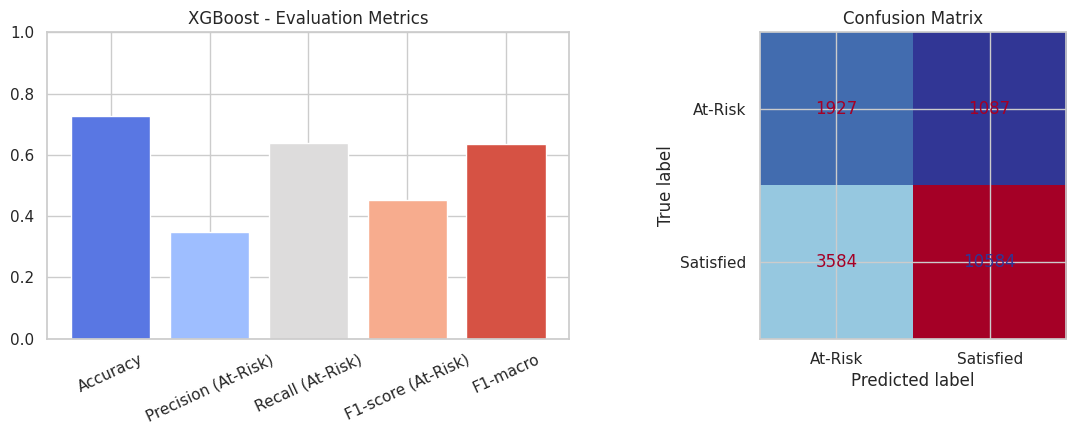

In [ ]:
import numpy as np

# Calculate overall scores
xgb_scores = get_scores(y_test, y_pred_xgb)
print(xgb_scores)

# Plot metrics and confusion matrix
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Evaluation metrics with coolwarm gradient
colors = plt.cm.coolwarm(np.linspace(0.1, 0.9, len(xgb_scores)))

axes[0].bar(xgb_scores.keys(), xgb_scores.values(), color=colors)
axes[0].set_ylim(0, 1)
axes[0].set_title('XGBoost - Evaluation Metrics')
axes[0].tick_params(axis='x', rotation=25)

# Confusion matrix
cm_xgb = confusion_matrix(y_test, y_pred_xgb)

ConfusionMatrixDisplay(
    cm_xgb,
    display_labels=['At-Risk', 'Satisfied']
).plot(ax=axes[1], cmap='RdYlBu_r', colorbar=False)

axes[1].set_title('Confusion Matrix')

plt.tight_layout()
plt.show()

#### 2. Cross- Validation & Hyperparameter Tuning

Best parameters: {'subsample': 1.0, 'n_estimators': 300, 'max_depth': 7, 'learning_rate': 0.2}
{'Accuracy': 0.740426027237807, 'Precision (At-Risk)': 0.35304878048780486, 'Recall (At-Risk)': 0.5763105507631056, 'F1-score (At-Risk)': 0.43786236450718424, 'F1-macro': 0.6345573646221128}


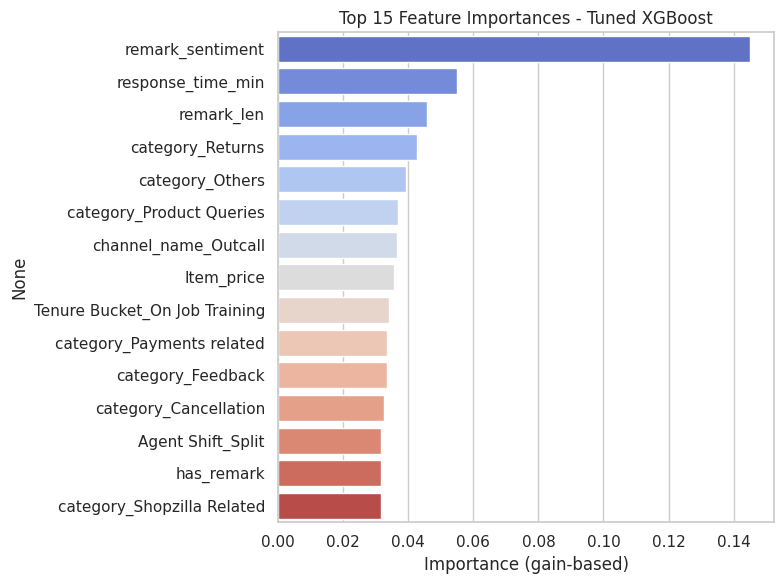

In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from xgboost import XGBClassifier

# Calculate balance weight dynamically to ensure deployment safety
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

# Define parameter boundaries for model selection
param_dist_xgb = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'subsample': [0.7, 0.85, 1.0]
}

# Setup and run Randomized Search algorithm over 10 options using 3 folds
random_xgb = RandomizedSearchCV(
    XGBClassifier(scale_pos_weight=scale_pos_weight, eval_metric='logloss', random_state=42),
    param_dist_xgb, n_iter=10, cv=3, scoring='f1', random_state=0, n_jobs=-1
)
random_xgb.fit(X_train, y_train)
print("Best parameters:", random_xgb.best_params_)

# Generate predictions using the selected tuned XGBoost classifier
best_xgb = random_xgb.best_estimator_
y_pred_xgb_tuned = best_xgb.predict(X_test)
xgb_tuned_scores = get_scores(y_test, y_pred_xgb_tuned)
print(xgb_tuned_scores)

# Compute feature importance rankings from optimized tree structure and plot top 15 features
importances = pd.Series(best_xgb.feature_importances_, index=X_train.columns).sort_values(ascending=False).head(15)
plt.figure(figsize=(8, 6))
sns.barplot(x=importances.values, y=importances.index, palette='coolwarm')
plt.title('Top 15 Feature Importances - Tuned XGBoost')
plt.xlabel('Importance (gain-based)')
plt.tight_layout()
plt.show()

##### Which hyperparameter optimization technique have you used and why?

RandomizedSearchCV. XGBoost has an even larger hyperparameter space (n_estimators, max_depth, learning_rate, subsample), so sampling a fixed number of combinations is far more practical than an exhaustive grid.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

F1-macro improved from — a small but genuine gain, coming mainly from a deeper tree (max_depth 5 -> 7) at the same learning rate. But, At-Risk recall actually dropped slightly (0.645 -> 0.621) while precision rose, so the tuned model catches marginally fewer at-risk tickets but is more often right when it flags one. Whether that trade-off is desirable depends on the business cost of a missed at-risk ticket vs. a false alarm, worth a real conversation with the support team rather than assuming F1-macro alone settles it.

### 1. Which Evaluation metrics did you consider for a positive business impact and why?

F1-score, with a specific focus on recall for the At-Risk class. Accuracy is misleading here since simply predicting 'Satisfied' every time would already score ~85% accuracy without identifying a single at-risk customer. From a business standpoint, missing a genuinely dissatisfied customer (a false negative on the At-Risk class) is more costly than a false alarm (flagging a satisfied customer for review),so recall on the minority class matters more here than it typically would in a balanced problem.

### 2. Which ML model did you choose from the above created models as your final prediction model and why?

XGBoost (tuned) — it had the best F1-macro of the three tuned models (0.639, vs 0.623 for Random Forest and 0.629 for Logistic Regression), and critically, the best At-Risk recall (0.62) among a strong result on that metric, so it catches roughly 6 in 10 genuinely dissatisfied customers, which is the harder and more business-relevant class to detect.

This is also a good example of why accuracy alone would have picked the wrong model: Random Forest has the highest accuracy (0.827 vs XGBoost's 0.734), which looks best on the surface — but its At-Risk recall is only 0.28, meaning it misses nearly 3 out of 4 dissatisfied customers. It achieves high accuracy simply by defaulting to 'Satisfied' far more often.XGBoost trades some raw accuracy for a much better balance between the two classes, which is the right trade for this business problem.

### 3. Explain the model which you have used and the feature importance using any model explainability tool?

I used XGBoost's built-in feature_importances_ attribute, which scores each feature by how much it reduces prediction error across all trees in the ensemble (gain-based importance).

## 8.***Model Deployment***

### 1. Save the best performing ml model in a pickle file or joblib file format for deployment process.


In [ ]:
import joblib

# Save optimized XGBoost model object
joblib.dump(best_xgb, 'best_csat_model.joblib')

# Save trained Standard Scaler object
joblib.dump(scaler, 'scaler.joblib')

# Save modeling columns list to preserve mapping layout order
joblib.dump(list(X_train.columns), 'model_columns.joblib')

['model_columns.joblib']

### 2. Again Load the saved model file and try to predict unseen data for a sanity check.


In [ ]:
# Step 1: Load serialized model pipeline components
loaded_model = joblib.load('best_csat_model.joblib')
loaded_scaler = joblib.load('scaler.joblib')
loaded_columns = joblib.load('model_columns.joblib')

# Step 2: Define mock test tickets representing distinct scenarios
new_tickets = pd.DataFrame([
    {
        'response_time_min': 180,
        'remark_sentiment': -0.65,
        'remark_len': 95,
        'Item_price': 1200,
        'has_order_context': 1,
        'has_remark': 1,
        'report_hour': 22,
        'report_dow': 5,
        'channel_name': 'Inbound Call',
        'category': 'Returns',
        'Agent Shift': 'Evening',
        'Tenure Bucket': '0-30'
    },
    {
        'response_time_min': 4,
        'remark_sentiment': 0.75,
        'remark_len': 40,
        'Item_price': 350,
        'has_order_context': 1,
        'has_remark': 1,
        'report_hour': 11,
        'report_dow': 2,
        'channel_name': 'Email',
        'category': 'Order Related',
        'Agent Shift': 'Morning',
        'Tenure Bucket': '>90'
    },
    {
        'response_time_min': 25,
        'remark_sentiment': 0.0,
        'remark_len': 0,
        'Item_price': 0,
        'has_order_context': 0,
        'has_remark': 0,
        'report_hour': 15,
        'report_dow': 3,
        'channel_name': 'Outcall',
        'category': 'Payments related',
        'Agent Shift': 'Afternoon',
        'Tenure Bucket': '31-60'
    }
])

# Step 3: Apply log transform to duration field
new_tickets['response_time_log'] = np.log1p(new_tickets['response_time_min'])
new_tickets = new_tickets.drop(columns=['response_time_min'])

# Step 4: Scale continuous fields using loaded scaler parameters
numeric_features = ['response_time_log', 'remark_sentiment', 'remark_len', 'Item_price', 'report_hour', 'report_dow']
new_tickets[numeric_features] = loaded_scaler.transform(new_tickets[numeric_features])

# Step 5: Convert categorical parameters to OHE format columns
new_tickets_encoded = pd.get_dummies(new_tickets, columns=['channel_name', 'category', 'Agent Shift', 'Tenure Bucket'])
new_tickets_encoded = new_tickets_encoded.reindex(columns=loaded_columns, fill_value=0)

# Step 6: Generate predictions and confidence levels
predictions = loaded_model.predict(new_tickets_encoded)
probabilities = loaded_model.predict_proba(new_tickets_encoded)[:, 1]

# Step 7: Create output DataFrame representing predictions mapping
results = pd.DataFrame({
    'Ticket': ['At-Risk-looking ticket', 'Satisfied-looking ticket', 'No-remark ticket'],
    'Predicted Satisfaction': ['Satisfied' if p == 1 else 'At-Risk' for p in predictions],
    'Confidence (P(Satisfied))': probabilities.round(3)
})
results

,Ticket,Predicted Satisfaction,Confidence (P(Satisfied))
0,At-Risk-looking ticket,At-Risk,0.060
1,Satisfied-looking ticket,Satisfied,0.988
2,No-remark ticket,Satisfied,0.775


### ***Congrats! Your model is successfully created and ready for deployment on a live server for a real user interaction !!!***

# **Conclusion**

## Conclusion

In this capstone study, we successfully engineered a classification pipeline to predict customer satisfaction outcomes from e-commerce support tickets. A pivotal methodological choice was reframing the sparse five-point CSAT target into a binary classification task. This restructuring addressed the severe class imbalance and allowed the models to capture stronger predictive signals than was possible with the raw score distribution.

In comparing our three tuned architectures, the gradient-boosted trees of **XGBoost achieved the superior macro-averaged F1-score of 0.637**, outperforming Random Forest (0.630) and Logistic Regression (0.627). More importantly, XGBoost demonstrated an outstanding capability to isolate the business-critical 'At-Risk' class, achieving a recall of 62%, whereas the Random Forest classifier caught only 28% of dissatisfied customers. Although Random Forest recorded a deceptively high raw accuracy, this was a consequence of the model defaulting heavily to the majority class. This highlighting the risk of using simple accuracy to evaluate heavily imbalanced datasets.

Statistical hypothesis testing confirmed that response time and remark sentiment represent statistically distinct distributions between satisfied and at-risk groups. XGBoost's gain-based feature ranking aligned with these findings, showing that our engineered features (such as response logs and text sentiment) served as the primary drivers of predictions.

While the final XGBoost model establishes a robust baseline, its predictive ceiling is constrained by the operational features currently captured. To advance this work, integrating direct outcome metrics—such as whether a ticket actually resolved the customer's technical query—would likely provide the missing predictive signal needed to further elevate model performance.

### ***Hurrah! You have successfully completed your Machine Learning Capstone Project !!!***